# MAIA — EDA Ambiental para Solo Úmido, Água e Contexto Geoespacial

## Fases 0 a 4

Este notebook inaugura a frente ambiental do MAIA.

A proposta é construir uma base real e rastreável de contexto do terreno para complementar a telemetria dos tratores.

### Fontes planejadas

- Google Earth Engine;
- Sentinel-1 SAR;
- Sentinel-2;
- JRC Global Surface Water;
- SRTM;
- SoilGrids;
- Open-Meteo.

### Estrutura completa planejada

0. Ambiente, bibliotecas, `venv` e autenticação do Google Earth Engine
1. Definição do problema e hipóteses
2. Fontes de dados, papel e limitações
3. Configuração Python / Earth Engine e validação do ambiente
4. Localização da fazenda e construção da AOI
5. Sentinel-1 SAR — VV / VH
6. Sentinel-2 — NDWI / NDMI + proximidade de água
7. SRTM — elevação e declividade
8. SoilGrids — textura e propriedades do solo
9. Open-Meteo — chuva antecedente
10. Integração e EDA multivariado
11. Validação final da limpeza e prontidão para ML

> Nesta etapa não haverá treinamento de Machine Learning nem criação de rótulo artificial de atolamento.

# FASE 0 — Ambiente, bibliotecas e Google Earth Engine

Esta fase existe para evitar que o restante do notebook dependa de um ambiente mal configurado.

Antes de consultar qualquer satélite, precisamos garantir que:

1. o projeto esteja usando o `venv` correto;
2. o Jupyter esteja executando com o Python desse `venv`;
3. a API Python do Earth Engine esteja instalada;
4. o pacote `geemap` esteja disponível para visualização;
5. o projeto Google Cloud esteja configurado;
6. a autenticação local tenha sido concluída;
7. o `GEE_PROJECT_ID` esteja disponível no `.env`;
8. a conexão com o Earth Engine funcione de verdade.

---

## 0.1 — O que é `earthengine-api`?

O pacote:

```text
earthengine-api
```

é o cliente Python oficial do Google Earth Engine.

Depois da instalação, ele é importado como:

```python
import ee
```

Ele permite ao Python criar objetos remotos do Earth Engine, por exemplo:

```python
ee.Image(...)
ee.ImageCollection(...)
ee.Feature(...)
ee.FeatureCollection(...)
ee.Geometry(...)
```

Grande parte das operações não acontece localmente na máquina.

O Python descreve a operação e o processamento é executado na infraestrutura do Earth Engine.

Por isso existe uma diferença importante entre:

```python
objeto = ee.Image(...)
```

e:

```python
objeto.getInfo()
```

O primeiro normalmente cria uma representação remota.

O segundo solicita ao servidor que devolva o resultado para o Python local.

### Regra prática

Evitar `getInfo()` em grandes coleções ou imagens inteiras.

No EDA utilizaremos `reduceRegion`, `reduceRegions`, agregações e filtros antes de trazer resultados para o Pandas.

Documentação oficial:

https://developers.google.com/earth-engine/guides/python_install

## 0.2 — O que é `geemap`?

`geemap` é uma biblioteca Python criada para facilitar o uso do Earth Engine em ambientes como Jupyter Notebook e JupyterLab.

Ela ajuda principalmente em:

- mapas interativos;
- visualização de imagens do Earth Engine;
- inspeção espacial;
- desenho de pontos/polígonos;
- conversões e exportações;
- exploração visual de camadas.

Ela **não substitui** `earthengine-api`.

A relação é:

```text
earthengine-api
        ↓
API oficial / processamento

geemap
        ↓
visualização e ferramentas auxiliares em Python/Jupyter
```

Documentação:

https://geemap.org/

## 0.4 — Ativar o `venv` no Debian/Linux

No terminal, dentro da raiz do projeto:

```bash
cd ~/Documentos/maia-intelligence-NEXT
```

Se o `venv` já existe:

```bash
source venv/bin/activate
```

O terminal deve passar a mostrar algo parecido com:

```text
(venv) debianjv@debian:~/Documentos/maia-intelligence-NEXT$
```

### Se o `venv` ainda não existisse

```bash
python3 -m venv venv
source venv/bin/activate
```

Depois confirme:

```bash
which python
python --version
python -m pip -V
```

O `which python` deve apontar para algo como:

```text
.../maia-intelligence-NEXT/venv/bin/python
```

## 0.5 — Instalar as bibliotecas no `venv`

Com o `venv` ativo:

```bash
python -m pip install --upgrade pip
```

Depois:

```bash
python -m pip install earthengine-api geemap requests python-dotenv pandas numpy matplotlib ipykernel
```

Para conferir:

```bash
python -m pip show earthengine-api
python -m pip show geemap
```

Também vale verificar onde o CLI do Earth Engine foi instalado:

```bash
which earthengine
```

Ele deve apontar para o executável dentro do `venv`.

### Reprodutibilidade

Depois de confirmar que tudo funciona, as dependências podem ser registradas no `requirements.txt`.

Por exemplo:

```bash
python -m pip freeze > requirements.txt
```

No projeto real, prefira revisar esse arquivo antes de commitar para evitar dependências desnecessárias.

## 0.6 — Fazer o Jupyter usar o mesmo `venv`

Esse ponto é muito importante.

É possível ativar o `venv` no terminal e, mesmo assim, o notebook estar usando outro Python.

Com o `venv` ativo:

```bash
python -m ipykernel install \
  --user \
  --name maia-venv \
  --display-name "Python (MAIA venv)"
```

Depois, no VS Code:

```text
Notebook
→ Select Kernel
→ Python Environments
→ Python (MAIA venv)
```

O notebook deve executar usando o mesmo interpretador no qual instalamos `earthengine-api`.

In [1]:
# Validação do interpretador que está executando este notebook.

import sys
from pathlib import Path

print("Python executando o notebook:")
print(sys.executable)
print()

print("Versão:")
print(sys.version)
print()

esta_no_venv = (
    "venv" in str(Path(sys.executable)).lower()
)

print("Parece estar no venv:", esta_no_venv)

if not esta_no_venv:
    print()
    print(
        "ATENÇÃO: confirme o Kernel do notebook no VS Code."
    )

Python executando o notebook:
c:\Users\Kevin\OneDrive\Desktop\maia-intelligence-NEXT\venv\Scripts\python.exe

Versão:
3.11.9 (tags/v3.11.9:de54cf5, Apr  2 2024, 10:12:12) [MSC v.1938 64 bit (AMD64)]

Parece estar no venv: True


In [2]:
# Auditoria das bibliotecas essenciais.

from importlib.metadata import version, PackageNotFoundError

pacotes = [
    "earthengine-api",
    "geemap",
    "requests",
    "python-dotenv",
    "pandas",
    "numpy",
    "matplotlib",
    "ipykernel",
]

resultado = []

for pacote in pacotes:
    try:
        versao = version(pacote)
        status = "OK"
    except PackageNotFoundError:
        versao = None
        status = "NÃO INSTALADO"

    resultado.append(
        {
            "pacote": pacote,
            "status": status,
            "versao": versao,
        }
    )

import pandas as pd

pd.DataFrame(resultado)

,pacote,status,versao
0,earthengine-api,OK,1.7.45
1,geemap,OK,0.37.2
2,requests,OK,2.34.2
3,python-dotenv,OK,1.2.3
4,pandas,OK,3.0.6
5,numpy,OK,2.4.6
6,matplotlib,OK,3.11.2
7,ipykernel,OK,7.3.0


## 0.7 — Projeto Google Earth Engine utilizado no MAIA

O projeto cadastrado para esta etapa é:

```text
Project ID:
canvas-setup-459119-u5
```

No `.env` da raiz do projeto, adicionar:

```env
GEE_PROJECT_ID=canvas-setup-459119-u5
```

Não é senha.

É apenas o identificador público do Google Cloud Project que será usado pelo `ee.Initialize(...)`.

## 0.8 — Autenticação local

Com o `venv` ativo:

```bash
earthengine authenticate
```

O comando abre o fluxo de autorização da conta Google.

Depois:

```bash
earthengine set_project canvas-setup-459119-u5
```

### Alternativa pelo Python

Também é possível iniciar o fluxo com:

```python
import ee
ee.Authenticate()
```

Depois:

```python
ee.Initialize(
    project="canvas-setup-459119-u5"
)
```

A autenticação não precisa ser executada em toda célula do notebook.

O objetivo é autenticar a máquina e depois apenas inicializar o cliente nas execuções futuras.

Documentação oficial:

https://developers.google.com/earth-engine/tutorials/community/intro-to-python-api

## 0.9 — Segurança e Git

O `.env` deve permanecer fora do versionamento.

Confirme que o `.gitignore` contém:

```gitignore
.env
venv/
.venv/
__pycache__/
.ipynb_checkpoints/
```

Nunca coloque no notebook:

- senha do Google;
- token OAuth;
- chave de service account;
- arquivos JSON privados de credenciais.

O `GEE_PROJECT_ID` pode ficar no `.env` por organização, mas ele não é uma senha.

## 0.10 — Diagnóstico rápido pelo terminal

Antes de rodar o EDA, estes comandos devem funcionar:

```bash
source venv/bin/activate

which python
which earthengine

python -c "import ee; print(ee.__version__)"
python -c "import geemap; print(geemap.__version__)"
```

Depois:

```bash
earthengine authenticate
earthengine set_project canvas-setup-459119-u5
```

Se tudo estiver correto, avançamos para a validação dentro do notebook.

# FASE 1 — Definição do problema

## 1.1 — Problema

No MAIA queremos estimar melhor o contexto de risco operacional do terreno.

Uma previsão meteorológica isolada não representa o estado real da superfície.

O solo pode continuar molhado mesmo sem chuva no momento porque depende de:

- precipitação antecedente;
- drenagem;
- textura;
- relevo;
- vegetação;
- proximidade de água;
- retenção hídrica;
- histórico recente do local.

## 1.2 — Pergunta principal do EDA

> Quais condições observadas por satélite, clima, solo e relevo estão associadas a maior presença de água e umidade superficial na área de operação?

## 1.3 — Hipótese de trabalho

Nenhuma variável será usada isoladamente.

O contexto ambiental será construído como:

```text
Sentinel-1 SAR
+
Sentinel-2
+
água histórica
+
relevo
+
solo
+
chuva antecedente
=
contexto ambiental multivariável
```

## 1.4 — Limites da etapa

Nesta fase:

- não treinaremos modelo;
- não criaremos target artificial;
- não afirmaremos que radar mede diretamente umidade volumétrica;
- não definiremos um limiar universal de "solo perigoso";
- não confundiremos centro da cidade com localização da fazenda.

# FASE 2 — Fontes de dados e papel de cada uma

## 2.1 — Sentinel-1 SAR

Earth Engine:

```text
COPERNICUS/S1_GRD
```

Usaremos inicialmente:

- VV;
- VH;
- angle;
- órbita;
- data/hora.

Objetivo:

analisar o comportamento radar da superfície ao longo do tempo.

Importante:

VV e VH são influenciados por vários fatores, incluindo:

- umidade;
- rugosidade;
- vegetação;
- geometria;
- ângulo de incidência.

Logo, não serão convertidos ingenuamente em "% de umidade".

Fonte:

https://developers.google.com/earth-engine/datasets/catalog/COPERNICUS_S1_GRD

## 2.2 — Sentinel-2

Earth Engine:

```text
COPERNICUS/S2_SR_HARMONIZED
```

Índices planejados:

### NDWI

```text
(B3 - B8) / (B3 + B8)
```

Uso principal:

detecção/contexto de água superficial.

### NDMI

```text
(B8 - B11) / (B8 + B11)
```

Uso:

informação complementar relacionada ao conteúdo de água na cobertura/vegetação.

Fonte:

https://developers.google.com/earth-engine/datasets/catalog/COPERNICUS_S2_SR_HARMONIZED

## 2.3 — JRC Global Surface Water

Earth Engine:

```text
JRC/GSW1_4/GlobalSurfaceWater
```

Variáveis úteis:

- occurrence;
- seasonality;
- recurrence;
- max_extent.

Objetivo:

adicionar contexto histórico de presença de água e futuramente calcular distância até água histórica.

Fonte:

https://developers.google.com/earth-engine/datasets/catalog/JRC_GSW1_4_GlobalSurfaceWater

## 2.4 — SRTM

Earth Engine:

```text
USGS/SRTMGL1_003
```

Features planejadas:

- elevação;
- declividade;
- relevo local;
- elevação relativa à vizinhança.

Objetivo:

distinguir, por exemplo:

- baixadas;
- regiões planas;
- áreas de encosta.

Fonte:

https://developers.google.com/earth-engine/datasets/catalog/USGS_SRTMGL1_003

## 2.5 — SoilGrids

Fonte:

ISRIC SoilGrids.

Propriedades de interesse:

- clay;
- sand;
- silt;
- bulk density;
- organic carbon.

Uso:

fornecer contexto relativamente estático sobre propriedades do solo.

Fonte:

https://docs.isric.org/globaldata/soilgrids/access_on_gee.html

## 2.6 — Open-Meteo

Usaremos inicialmente:

- precipitação diária;
- chuva acumulada em 3 dias;
- chuva acumulada em 7 dias;
- chuva acumulada em 14 dias;
- umidade do solo de reanálise como referência externa.

A umidade fornecida por modelo meteorológico não será confundida com medição local do talhão.

Fonte:

https://open-meteo.com/en/docs/historical-weather-api

# FASE 3 — Configuração Python e validação real do Earth Engine

A Fase 0 preparou o ambiente.

Agora validamos programaticamente se o notebook consegue conversar com o Google Earth Engine.

In [4]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests

import ee
import geemap

from dotenv import load_dotenv

pd.set_option(
    "display.max_columns",
    None
)

pd.set_option(
    "display.float_format",
    lambda x: f"{x:.4f}"
)

In [6]:
# Procura a raiz do projeto a partir do diretório atual.

CURRENT_PATH = Path.cwd().resolve()

PROJECT_ROOT = CURRENT_PATH

for candidato in [
    CURRENT_PATH,
    *CURRENT_PATH.parents
]:
    if (
        (candidato / ".git").exists()
        or (candidato / ".env").exists()
    ):
        PROJECT_ROOT = candidato
        break

ENV_PATH = PROJECT_ROOT / ".env"

if ENV_PATH.exists():
    load_dotenv(
        ENV_PATH,
        override=False
    )

print(
    "PROJECT_ROOT:",
    PROJECT_ROOT
)

print(
    ".env:",
    ENV_PATH
    if ENV_PATH.exists()
    else "não encontrado"
)

PROJECT_ROOT: C:\Users\Kevin\OneDrive\Desktop\maia-intelligence-NEXT
.env: C:\Users\Kevin\OneDrive\Desktop\maia-intelligence-NEXT\.env


In [7]:
GEE_PROJECT_ID = os.getenv(
    "GEE_PROJECT_ID"
)

if not GEE_PROJECT_ID:
    raise RuntimeError(
        "GEE_PROJECT_ID não encontrado. "
        "Adicione GEE_PROJECT_ID=canvas-setup-459119-u5 ao .env."
    )

print(
    "Google Cloud Project:",
    GEE_PROJECT_ID
)

Google Cloud Project: canvas-setup-459119-u5


In [8]:
# Inicialização do Earth Engine.
#
# Se a autenticação já foi feita no terminal,
# esta célula não deve abrir fluxo de login novamente.

try:
    ee.Initialize(
        project=GEE_PROJECT_ID
    )

    GEE_OK = True

    print(
        "Google Earth Engine inicializado com sucesso."
    )

except Exception as exc:
    GEE_OK = False

    print(
        "Falha ao inicializar o Earth Engine."
    )
    print()
    print(
        "No terminal com o venv ativo, execute:"
    )
    print(
        "earthengine authenticate"
    )
    print(
        f"earthengine set_project {GEE_PROJECT_ID}"
    )
    print()
    print(
        "Erro:"
    )
    print(
        repr(exc)
    )

*** Earth Engine *** Share your feedback by taking our Annual Developer Satisfaction Survey: https://google.qualtrics.com/jfe/form/SV_9oS0DRcPvElRMNw?source=python


Google Earth Engine inicializado com sucesso.


In [9]:
def exigir_gee():
    if not GEE_OK:
        raise RuntimeError(
            "Earth Engine ainda não está disponível. "
            "Corrija a autenticação antes de continuar."
        )


exigir_gee()

# Teste simples com SRTM.
teste_srtm = ee.Image(
    "USGS/SRTMGL1_003"
)

bandas = (
    teste_srtm
    .bandNames()
    .getInfo()
)

print(
    "Dataset de teste acessado com sucesso."
)

print(
    "Bandas SRTM:",
    bandas
)

Dataset de teste acessado com sucesso.
Bandas SRTM: ['elevation']


## 3.1 — Teste opcional com `geemap`

Se o Jupyter estiver com suporte aos widgets, esta célula deverá exibir um mapa interativo.

Ela não é necessária para o processamento do Earth Engine, mas será útil na inspeção visual das áreas.

In [10]:
exigir_gee()

Map = geemap.Map(
    center=[
        -15.0,
        -47.0
    ],
    zoom=4
)

Map.addLayer(
    teste_srtm,
    {
        "min": 0,
        "max": 2500,
    },
    "SRTM"
)

Map

Map(center=[-15.0, -47.0], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright'…

# FASE 4 — Localização da fazenda e Área de Interesse

Os dados de satélite dependem de coordenadas.

Por isso esta fase separa dois conceitos.

## 4.1 — Validação administrativa

Ao cadastrar uma fazenda, o backend poderá validar:

- cidade;
- estado;
- país;
- endereço/CEP, quando houver suporte.

## 4.2 — Localização geoespacial

Para consultar o satélite precisamos de:

- latitude/longitude real da fazenda; ou, idealmente,
- polígono GeoJSON do talhão.

O centro de uma cidade pode servir para teste técnico, mas não para análise final de uma propriedade agrícola.

## 4.3 — Prova de conceito: geocoding de cidade

Nesta primeira etapa usaremos a API de geocoding do Open-Meteo apenas para validar município e obter coordenadas aproximadas.

Endpoint:

```text
https://geocoding-api.open-meteo.com/v1/search
```

A documentação permite pesquisar localidades e códigos postais.

Fonte:

https://open-meteo.com/en/docs/geocoding-api

In [11]:
def geocodificar_cidade(
    cidade,
    estado=None,
    country_code="BR",
    timeout=20
):
    consulta = cidade.strip()

    if estado:
        consulta = (
            f"{consulta}, {estado.strip()}"
        )

    resposta = requests.get(
        "https://geocoding-api.open-meteo.com/v1/search",
        params={
            "name": consulta,
            "count": 10,
            "language": "pt",
            "format": "json",
            "countryCode": country_code,
        },
        timeout=timeout,
    )

    resposta.raise_for_status()

    payload = resposta.json()

    resultados = payload.get(
        "results",
        []
    )

    if not resultados:
        raise ValueError(
            f"Nenhum local encontrado para: {consulta}"
        )

    return pd.DataFrame(
        resultados
    )

In [12]:
# Teste do geocoder.

cidade_teste = geocodificar_cidade(
    cidade="Ribeirão Preto",
    estado="São Paulo",
    country_code="BR",
)

colunas_exibir = [
    coluna
    for coluna in [
        "name",
        "latitude",
        "longitude",
        "admin1",
        "admin2",
        "country",
        "timezone",
    ]
    if coluna in cidade_teste.columns
]

cidade_teste[
    colunas_exibir
].head(10)

,name,latitude,longitude,admin1,admin2,country,timezone
0,Ribeirão Preto,-21.1775,-47.8103,São Paulo,Ribeirão Preto,Brasil,America/Sao_Paulo


## 4.4 — Configuração da fazenda para o EDA

Para a análise final, substituir `None` pelas coordenadas reais da propriedade.

Enquanto isso, o notebook poderá usar o centro da cidade **somente como teste de integração**.

In [13]:
FAZENDA = {
    "nome": "Fazenda_Teste",
    "cidade": "Ribeirão Preto",
    "estado": "São Paulo",
    "country_code": "BR",

    # PREENCHER com localização real antes da análise final.
    "latitude": None,
    "longitude": None,
}

AOI_BUFFER_M = 500

In [14]:
if (
    FAZENDA["latitude"] is None
    or FAZENDA["longitude"] is None
):
    candidatos = geocodificar_cidade(
        cidade=FAZENDA["cidade"],
        estado=FAZENDA["estado"],
        country_code=FAZENDA["country_code"],
    )

    escolhido = candidatos.iloc[0]

    LATITUDE = float(
        escolhido["latitude"]
    )

    LONGITUDE = float(
        escolhido["longitude"]
    )

    LOCALIZACAO_PRECISA = False

    print(
        "ATENÇÃO: centro aproximado da cidade usado apenas para teste."
    )

else:
    LATITUDE = float(
        FAZENDA["latitude"]
    )

    LONGITUDE = float(
        FAZENDA["longitude"]
    )

    LOCALIZACAO_PRECISA = True


if not (
    -90 <= LATITUDE <= 90
    and -180 <= LONGITUDE <= 180
):
    raise ValueError(
        "Latitude ou longitude inválida para WGS84."
    )


print(
    "Latitude:",
    LATITUDE
)

print(
    "Longitude:",
    LONGITUDE
)

print(
    "Localização precisa:",
    LOCALIZACAO_PRECISA
)

ATENÇÃO: centro aproximado da cidade usado apenas para teste.
Latitude: -21.1775
Longitude: -47.81028
Localização precisa: False


In [15]:
exigir_gee()

PONTO_FAZENDA = ee.Geometry.Point(
    [
        LONGITUDE,
        LATITUDE
    ]
)

AOI = PONTO_FAZENDA.buffer(
    AOI_BUFFER_M
)

print(
    "Ponto criado no Earth Engine."
)

print(
    f"AOI criada com buffer de {AOI_BUFFER_M} metros."
)

Ponto criado no Earth Engine.
AOI criada com buffer de 500 metros.


## 4.5 — Visualização da AOI

Esta célula permite confirmar visualmente se o ponto está no local esperado.

In [16]:
Map_fazenda = geemap.Map(
    center=[
        LATITUDE,
        LONGITUDE
    ],
    zoom=14
)

Map_fazenda.addLayer(
    PONTO_FAZENDA,
    {},
    "Ponto da fazenda"
)

Map_fazenda.addLayer(
    AOI,
    {},
    "AOI"
)

Map_fazenda

Map(center=[-21.1775, -47.81028], controls=(WidgetControl(options=['position', 'transparent_bg'], position='to…

# FASE 5 — Sentinel-1 SAR: VV, VH e comportamento temporal

A partir daqui começa a extração real de dados ambientais para o MAIA.

O Sentinel-1 será a principal fonte dinâmica para observar mudanças da superfície porque utiliza radar SAR em banda C e não depende de iluminação solar.

## 5.1 — Objetivo

Construir uma série temporal homogênea de:

- `VV`;
- `VH`;
- `VV - VH`;
- ângulo de incidência;
- direção da órbita;
- número de pixels válidos;
- estatísticas espaciais dentro da AOI.

## 5.2 — Cuidados metodológicos

Não vamos interpretar `VV` ou `VH` como "% de umidade".

O backscatter também é influenciado por:

- rugosidade;
- vegetação;
- geometria da superfície;
- ângulo de incidência;
- direção da órbita;
- estado da cultura.

Por isso, nesta EDA vamos observar:

1. nível absoluto do sinal;
2. mudança temporal;
3. diferença em relação ao histórico da própria área;
4. coerência com chuva, Sentinel-2, relevo e solo.

## 5.3 — Coleção

```text
COPERNICUS/S1_GRD
```

Filtros aplicados:

- modo `IW`;
- resolução de 10 m;
- polarização `VV`;
- polarização `VH`;
- interseção com a AOI;
- período definido pelo projeto.

In [17]:
# ============================================================
# PERÍODO PRINCIPAL DA EDA
# ============================================================

# Para manter o notebook reproduzível e evitar os últimos dias
# ainda não consolidados no histórico meteorológico, terminamos
# sete dias antes da execução.
DATA_FIM = (
    pd.Timestamp.today()
    .normalize()
    - pd.Timedelta(days=7)
)

DATA_INICIO = (
    DATA_FIM
    - pd.Timedelta(days=180)
)

DATA_INICIO_STR = DATA_INICIO.strftime("%Y-%m-%d")
DATA_FIM_STR = DATA_FIM.strftime("%Y-%m-%d")

# filterDate usa o limite final como exclusivo.
DATA_FIM_GEE_STR = (
    DATA_FIM
    + pd.Timedelta(days=1)
).strftime("%Y-%m-%d")

print("Período:")
print("Início:", DATA_INICIO_STR)
print("Fim:", DATA_FIM_STR)

if not LOCALIZACAO_PRECISA:
    print()
    print(
        "ATENÇÃO: a AOI ainda usa coordenada aproximada da cidade. "
        "Os resultados servem somente para validar o pipeline."
    )

Período:
Início: 2026-03-22
Fim: 2026-09-18

ATENÇÃO: a AOI ainda usa coordenada aproximada da cidade. Os resultados servem somente para validar o pipeline.


In [18]:
def obter_sentinel1(
    aoi,
    data_inicio,
    data_fim_exclusiva
):
    exigir_gee()

    colecao = (
        ee.ImageCollection(
            "COPERNICUS/S1_GRD"
        )
        .filterBounds(aoi)
        .filterDate(
            data_inicio,
            data_fim_exclusiva
        )
        .filter(
            ee.Filter.eq(
                "instrumentMode",
                "IW"
            )
        )
        .filter(
            ee.Filter.eq(
                "resolution_meters",
                10
            )
        )
        .filter(
            ee.Filter.listContains(
                "transmitterReceiverPolarisation",
                "VV"
            )
        )
        .filter(
            ee.Filter.listContains(
                "transmitterReceiverPolarisation",
                "VH"
            )
        )
        .select(
            [
                "VV",
                "VH",
                "angle"
            ]
        )
    )

    return colecao


s1 = obter_sentinel1(
    AOI,
    DATA_INICIO_STR,
    DATA_FIM_GEE_STR
)

qtd_s1 = s1.size().getInfo()

print(
    "Cenas Sentinel-1 encontradas:",
    qtd_s1
)

if qtd_s1 == 0:
    raise RuntimeError(
        "Nenhuma cena Sentinel-1 encontrada. "
        "Confira período, coordenadas e AOI."
    )

Cenas Sentinel-1 encontradas: 35


## 5.4 — Inventário das cenas Sentinel-1

Antes de analisar os valores, verificamos:

- quantidade de imagens;
- datas;
- órbita ascendente/descendente;
- número relativo da órbita.

Isso é importante porque séries de geometrias diferentes não devem ser tratadas como se fossem uma única condição de observação.

In [19]:
def inventariar_s1(colecao):
    def para_feature(img):
        return ee.Feature(
            None,
            {
                "date": img.date().format(
                    "YYYY-MM-dd HH:mm:ss"
                ),
                "orbit_pass": img.get(
                    "orbitProperties_pass"
                ),
                "relative_orbit": img.get(
                    "relativeOrbitNumber_start"
                ),
                "platform": img.get(
                    "platform_number"
                ),
            }
        )

    fc = ee.FeatureCollection(
        colecao.map(
            para_feature
        )
    )

    info = fc.getInfo()

    df = pd.DataFrame(
        [
            feature["properties"]
            for feature in info["features"]
        ]
    )

    if not df.empty:
        df["date"] = pd.to_datetime(
            df["date"],
            errors="coerce"
        )

        df["relative_orbit"] = pd.to_numeric(
            df["relative_orbit"],
            errors="coerce"
        )

        df = df.sort_values(
            "date"
        ).reset_index(
            drop=True
        )

    return df


df_s1_inventory = inventariar_s1(
    s1
)

display(
    df_s1_inventory.head()
)

print()
print("Cenas por direção:")
display(
    df_s1_inventory[
        "orbit_pass"
    ].value_counts(
        dropna=False
    )
)

print()
print("Órbitas relativas:")
display(
    df_s1_inventory[
        [
            "orbit_pass",
            "relative_orbit"
        ]
    ]
    .value_counts()
    .rename("cenas")
    .reset_index()
)

,date,orbit_pass,platform,relative_orbit
0,2026-03-27 08:37:33,DESCENDING,C,126
1,2026-04-02 08:38:29,DESCENDING,A,126
2,2026-04-08 08:37:33,DESCENDING,C,126
3,2026-04-14 08:38:29,DESCENDING,A,126
4,2026-04-20 08:37:50,DESCENDING,C,126



Cenas por direção:


orbit_pass
DESCENDING    35
Name: count, dtype: int64


Órbitas relativas:


,orbit_pass,relative_orbit,cenas
0,DESCENDING,126,35


## 5.5 — Extração das estatísticas espaciais

Para cada cena calcularemos dentro da AOI:

- média;
- mediana;
- desvio padrão;
- quantidade de pixels válidos.

Também calcularemos:

```text
VV - VH
```

em dB como uma feature relativa adicional.

Traremos somente as estatísticas agregadas ao Pandas, evitando baixar a imagem inteira.

In [20]:
S1_SCALE_M = 10


def extrair_serie_s1(
    colecao,
    aoi,
    scale=10
):
    reducer = (
        ee.Reducer.mean()
        .combine(
            reducer2=ee.Reducer.median(),
            sharedInputs=True
        )
        .combine(
            reducer2=ee.Reducer.stdDev(),
            sharedInputs=True
        )
        .combine(
            reducer2=ee.Reducer.count(),
            sharedInputs=True
        )
    )

    def imagem_para_feature(img):
        vv = img.select("VV")
        vh = img.select("VH")

        vv_minus_vh = (
            vv.subtract(vh)
            .rename("VV_minus_VH")
        )

        imagem = (
            vv
            .addBands(vh)
            .addBands(vv_minus_vh)
            .addBands(
                img.select("angle")
            )
        )

        stats = imagem.reduceRegion(
            reducer=reducer,
            geometry=aoi,
            scale=scale,
            bestEffort=True,
            maxPixels=10_000_000,
        )

        return ee.Feature(
            None,
            {
                "date": img.date().format(
                    "YYYY-MM-dd HH:mm:ss"
                ),
                "orbit_pass": img.get(
                    "orbitProperties_pass"
                ),
                "relative_orbit": img.get(
                    "relativeOrbitNumber_start"
                ),
                "platform": img.get(
                    "platform_number"
                ),

                "VV_mean_db": stats.get(
                    "VV_mean"
                ),
                "VV_median_db": stats.get(
                    "VV_median"
                ),
                "VV_std_db": stats.get(
                    "VV_stdDev"
                ),

                "VH_mean_db": stats.get(
                    "VH_mean"
                ),
                "VH_median_db": stats.get(
                    "VH_median"
                ),
                "VH_std_db": stats.get(
                    "VH_stdDev"
                ),

                "VV_minus_VH_mean_db": stats.get(
                    "VV_minus_VH_mean"
                ),
                "angle_mean_deg": stats.get(
                    "angle_mean"
                ),
                "valid_pixels": stats.get(
                    "VV_count"
                ),
            }
        )

    fc = ee.FeatureCollection(
        colecao.map(
            imagem_para_feature
        )
    )

    info = fc.getInfo()

    registros = [
        feature["properties"]
        for feature in info["features"]
    ]

    df = pd.DataFrame(
        registros
    )

    if df.empty:
        return df

    df["date"] = pd.to_datetime(
        df["date"],
        errors="coerce"
    )

    numericas = [
        coluna
        for coluna in df.columns
        if coluna not in [
            "date",
            "orbit_pass",
            "platform"
        ]
    ]

    for coluna in numericas:
        df[coluna] = pd.to_numeric(
            df[coluna],
            errors="coerce"
        )

    return (
        df
        .sort_values("date")
        .reset_index(drop=True)
    )


df_s1 = extrair_serie_s1(
    s1,
    AOI,
    S1_SCALE_M
)

print(
    "Observações Sentinel-1:",
    len(df_s1)
)

display(
    df_s1.head()
)

Observações Sentinel-1: 35


,VH_mean_db,VH_median_db,VH_std_db,VV_mean_db,VV_median_db,VV_minus_VH_mean_db,VV_std_db,angle_mean_deg,date,orbit_pass,platform,relative_orbit,valid_pixels
0,-10.4946,-10.6855,4.2270,-5.9233,-6.1866,4.5713,3.9558,40.7863,2026-03-27 08:37:33,DESCENDING,C,126,7928
1,-9.6005,-9.8817,4.3300,-4.6002,-4.8055,5.0002,4.0937,40.6361,2026-04-02 08:38:29,DESCENDING,A,126,7945
2,-10.3203,-10.6917,4.3286,-5.6714,-5.9382,4.6488,3.9955,40.7829,2026-04-08 08:37:33,DESCENDING,C,126,7934
3,-10.4961,-10.6256,4.2619,-5.5087,-5.8141,4.9875,3.8742,40.6335,2026-04-14 08:38:29,DESCENDING,A,126,7944
4,-10.2747,-10.5656,4.2078,-5.8466,-6.0609,4.4281,3.9426,40.6743,2026-04-20 08:37:50,DESCENDING,C,126,7942


## 5.6 — Auditoria da série Sentinel-1

In [21]:
auditoria_s1 = pd.DataFrame(
    {
        "variavel": df_s1.columns,
        "ausentes": [
            int(
                df_s1[coluna]
                .isna()
                .sum()
            )
            for coluna
            in df_s1.columns
        ],
        "percentual_ausente": [
            float(
                df_s1[coluna]
                .isna()
                .mean()
                * 100
            )
            for coluna
            in df_s1.columns
        ],
        "unicos": [
            int(
                df_s1[coluna]
                .nunique(
                    dropna=True
                )
            )
            for coluna
            in df_s1.columns
        ],
    }
)

display(
    auditoria_s1
)

print()
print("Estatísticas numéricas:")

display(
    df_s1.select_dtypes(
        include=np.number
    )
    .describe()
    .T
)

,variavel,ausentes,percentual_ausente,unicos
0,VH_mean_db,0,0.0000,35
1,VH_median_db,0,0.0000,35
2,VH_std_db,0,0.0000,35
3,VV_mean_db,0,0.0000,35
4,VV_median_db,0,0.0000,35
5,VV_minus_VH_mean_db,0,0.0000,35
6,VV_std_db,0,0.0000,35
7,angle_mean_deg,0,0.0000,35
8,date,0,0.0000,35
9,orbit_pass,0,0.0000,1



Estatísticas numéricas:


,count,mean,std,min,25%,50%,75%,max
VH_mean_db,35.0000,-10.3115,0.2730,-10.6606,-10.4829,-10.3721,-10.2641,-9.6005
VH_median_db,35.0000,-10.5996,0.2501,-11.1310,-10.6620,-10.6244,-10.6176,-9.8817
VH_std_db,35.0000,4.2773,0.0718,4.1413,4.2305,4.2585,4.3293,4.4276
VV_mean_db,35.0000,-5.5786,0.3140,-5.9347,-5.7650,-5.6714,-5.4565,-4.6002
VV_median_db,35.0000,-5.8029,0.3184,-6.1866,-5.9099,-5.8748,-5.7214,-4.8055
VV_minus_VH_mean_db,35.0000,4.7329,0.1730,4.4281,4.6100,4.7148,4.7927,5.2234
VV_std_db,35.0000,3.9883,0.0446,3.8742,3.9633,3.9918,4.0138,4.0937
angle_mean_deg,35.0000,40.6460,0.0558,40.5392,40.6324,40.6416,40.6761,40.7863
relative_orbit,35.0000,126.0000,0.0000,126.0000,126.0000,126.0000,126.0000,126.0000
valid_pixels,35.0000,7932.6286,6.2171,7921.0000,7928.0000,7932.0000,7936.5000,7945.0000


## 5.7 — Comparação por direção da órbita

A direção da órbita pode alterar a geometria de observação.

Por isso, a EDA mantém `ASCENDING` e `DESCENDING` identificadas.

In [22]:
resumo_orbita_s1 = (
    df_s1
    .groupby(
        "orbit_pass",
        dropna=False
    )
    .agg(
        observacoes=(
            "date",
            "count"
        ),
        vv_media=(
            "VV_mean_db",
            "mean"
        ),
        vv_mediana=(
            "VV_mean_db",
            "median"
        ),
        vh_media=(
            "VH_mean_db",
            "mean"
        ),
        angle_media=(
            "angle_mean_deg",
            "mean"
        ),
    )
    .reset_index()
)

resumo_orbita_s1

,orbit_pass,observacoes,vv_media,vv_mediana,vh_media,angle_media
0,DESCENDING,35,-5.5786,-5.6714,-10.3115,40.6460


## 5.8 — Anomalia relativa ao próprio histórico

Em vez de usar um valor absoluto universal de radar, calculamos a diferença de cada observação em relação à mediana da mesma direção de órbita.

Essas features **não são rótulos de umidade**.

Elas apenas indicam quanto a cena atual se afastou do comportamento típico observado na própria área.

In [23]:
df_s1 = df_s1.copy()

df_s1[
    "VV_baseline_median_db"
] = (
    df_s1
    .groupby(
        "orbit_pass"
    )[
        "VV_mean_db"
    ]
    .transform("median")
)

df_s1[
    "VH_baseline_median_db"
] = (
    df_s1
    .groupby(
        "orbit_pass"
    )[
        "VH_mean_db"
    ]
    .transform("median")
)

df_s1[
    "VV_anomaly_db"
] = (
    df_s1["VV_mean_db"]
    - df_s1[
        "VV_baseline_median_db"
    ]
)

df_s1[
    "VH_anomaly_db"
] = (
    df_s1["VH_mean_db"]
    - df_s1[
        "VH_baseline_median_db"
    ]
)

df_s1[
    [
        "date",
        "orbit_pass",
        "VV_mean_db",
        "VV_anomaly_db",
        "VH_mean_db",
        "VH_anomaly_db"
    ]
].head()

,date,orbit_pass,VV_mean_db,VV_anomaly_db,VH_mean_db,VH_anomaly_db
0,2026-03-27 08:37:33,DESCENDING,-5.9233,-0.2519,-10.4946,-0.1225
1,2026-04-02 08:38:29,DESCENDING,-4.6002,1.0712,-9.6005,0.7716
2,2026-04-08 08:37:33,DESCENDING,-5.6714,0.0000,-10.3203,0.0518
3,2026-04-14 08:38:29,DESCENDING,-5.5087,0.1627,-10.4961,-0.1241
4,2026-04-20 08:37:50,DESCENDING,-5.8466,-0.1752,-10.2747,0.0974


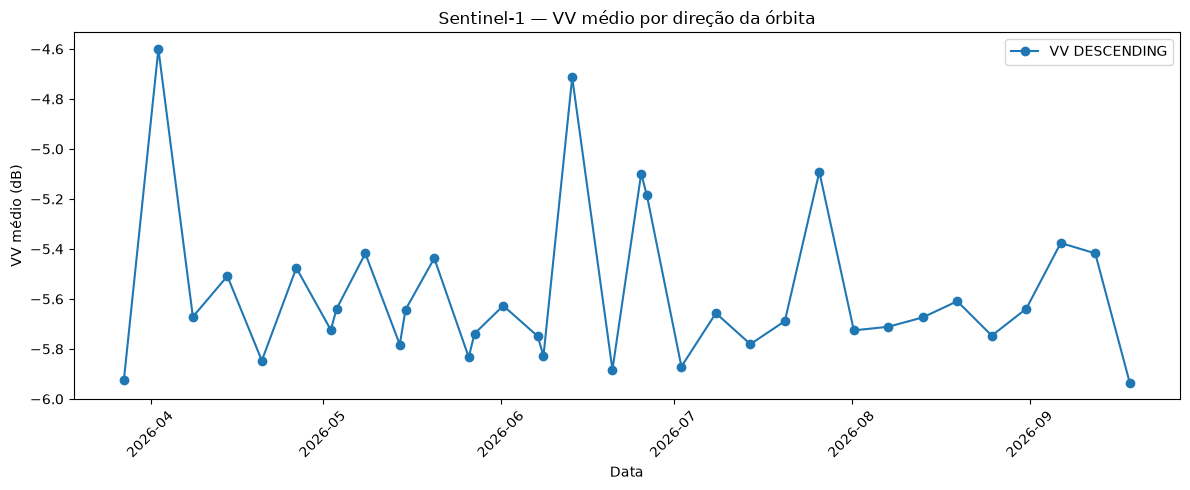

In [24]:
if not df_s1.empty:

    plt.figure(
        figsize=(12, 5)
    )

    for direcao, grupo in df_s1.groupby(
        "orbit_pass"
    ):
        plt.plot(
            grupo["date"],
            grupo["VV_mean_db"],
            marker="o",
            label=f"VV {direcao}"
        )

    plt.title(
        "Sentinel-1 — VV médio por direção da órbita"
    )
    plt.xlabel("Data")
    plt.ylabel("VV médio (dB)")
    plt.legend()
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

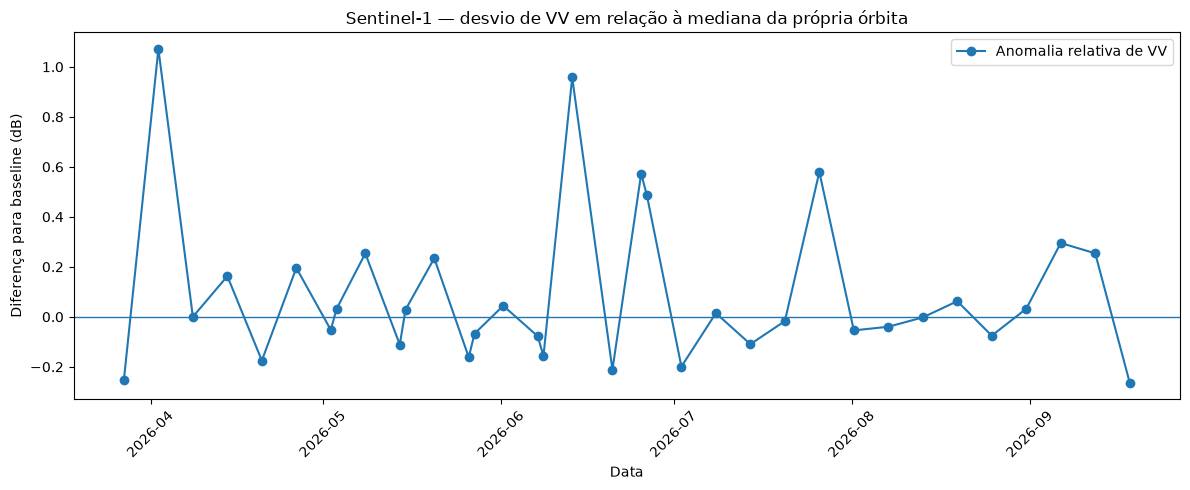

In [25]:
if not df_s1.empty:

    plt.figure(
        figsize=(12, 5)
    )

    plt.plot(
        df_s1["date"],
        df_s1["VV_anomaly_db"],
        marker="o",
        label="Anomalia relativa de VV"
    )

    plt.axhline(
        0,
        linewidth=1
    )

    plt.title(
        "Sentinel-1 — desvio de VV em relação à mediana da própria órbita"
    )
    plt.xlabel("Data")
    plt.ylabel("Diferença para baseline (dB)")
    plt.legend()
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

## 5.9 — Visualização da cena mais recente

A inspeção visual não substitui a análise estatística, mas ajuda a detectar:

- AOI errada;
- borda de cena;
- artefatos;
- localização incorreta.

In [26]:
ultima_s1 = (
    s1
    .sort(
        "system:time_start",
        False
    )
    .first()
)

Map_s1 = geemap.Map(
    center=[
        LATITUDE,
        LONGITUDE
    ],
    zoom=14
)

Map_s1.addLayer(
    ultima_s1.select("VV"),
    {
        "min": -25,
        "max": 5,
    },
    "Sentinel-1 VV"
)

Map_s1.addLayer(
    ultima_s1.select("VH"),
    {
        "min": -30,
        "max": 0,
    },
    "Sentinel-1 VH"
)

Map_s1.addLayer(
    AOI,
    {},
    "AOI"
)

Map_s1

Map(center=[-21.1775, -47.81028], controls=(WidgetControl(options=['position', 'transparent_bg'], position='to…

# FASE 6 — Sentinel-2, NDWI/NDMI e proximidade de água

O Sentinel-2 complementa o radar com informação óptica.

## 6.1 — Índices

### NDWI

```text
(B3 - B8) / (B3 + B8)
```

Uso nesta EDA:

- presença relativa de água superficial;
- mudança de condição espectral.

### NDMI

```text
(B8 - B11) / (B8 + B11)
```

Uso nesta EDA:

- contexto de conteúdo de água na cobertura/vegetação.

Nenhum dos dois será tratado como medição direta da umidade volumétrica do solo.

## 6.2 — Nuvens

Usaremos a coleção:

```text
COPERNICUS/S2_SR_HARMONIZED
```

e a classificação `SCL` para remover:

- no-data;
- pixels saturados/defeituosos;
- sombra de nuvem;
- nuvem;
- cirrus;
- neve/gelo.

Para uma versão futura ainda mais rigorosa, podemos adicionar `COPERNICUS/S2_CLOUD_PROBABILITY`.

In [27]:
S2_SCALE_M = 20
MAX_CLOUD_SCENE_PERCENT = 70


def mascarar_s2_scl(img):
    scl = img.select(
        "SCL"
    )

    mascara = (
        scl.neq(0)
        .And(scl.neq(1))
        .And(scl.neq(3))
        .And(scl.neq(8))
        .And(scl.neq(9))
        .And(scl.neq(10))
        .And(scl.neq(11))
    )

    return img.updateMask(
        mascara
    )


def adicionar_indices_s2(img):
    ndwi = (
        img.normalizedDifference(
            [
                "B3",
                "B8"
            ]
        )
        .rename("NDWI")
    )

    ndmi = (
        img.normalizedDifference(
            [
                "B8",
                "B11"
            ]
        )
        .rename("NDMI")
    )

    # Feature exploratória.
    # NDWI > 0 não é um classificador universal de água.
    ndwi_positive = (
        ndwi.gt(0)
        .rename(
            "NDWI_positive"
        )
    )

    return (
        img
        .addBands(ndwi)
        .addBands(ndmi)
        .addBands(ndwi_positive)
    )


s2 = (
    ee.ImageCollection(
        "COPERNICUS/S2_SR_HARMONIZED"
    )
    .filterBounds(AOI)
    .filterDate(
        DATA_INICIO_STR,
        DATA_FIM_GEE_STR
    )
    .filter(
        ee.Filter.lt(
            "CLOUDY_PIXEL_PERCENTAGE",
            MAX_CLOUD_SCENE_PERCENT
        )
    )
    .map(
        mascarar_s2_scl
    )
    .map(
        adicionar_indices_s2
    )
)

qtd_s2 = s2.size().getInfo()

print(
    "Cenas Sentinel-2 após filtros:",
    qtd_s2
)

Cenas Sentinel-2 após filtros: 72


In [28]:
def extrair_serie_s2(
    colecao,
    aoi,
    scale=20
):
    reducer = (
        ee.Reducer.mean()
        .combine(
            reducer2=ee.Reducer.median(),
            sharedInputs=True
        )
        .combine(
            reducer2=ee.Reducer.stdDev(),
            sharedInputs=True
        )
        .combine(
            reducer2=ee.Reducer.count(),
            sharedInputs=True
        )
    )

    def imagem_para_feature(img):
        stats = (
            img
            .select(
                [
                    "NDWI",
                    "NDMI",
                    "NDWI_positive"
                ]
            )
            .reduceRegion(
                reducer=reducer,
                geometry=aoi,
                scale=scale,
                bestEffort=True,
                maxPixels=10_000_000,
            )
        )

        return ee.Feature(
            None,
            {
                "date": img.date().format(
                    "YYYY-MM-dd HH:mm:ss"
                ),
                "cloud_pct_scene": img.get(
                    "CLOUDY_PIXEL_PERCENTAGE"
                ),

                "NDWI_mean": stats.get(
                    "NDWI_mean"
                ),
                "NDWI_median": stats.get(
                    "NDWI_median"
                ),
                "NDWI_std": stats.get(
                    "NDWI_stdDev"
                ),

                "NDMI_mean": stats.get(
                    "NDMI_mean"
                ),
                "NDMI_median": stats.get(
                    "NDMI_median"
                ),
                "NDMI_std": stats.get(
                    "NDMI_stdDev"
                ),

                "NDWI_positive_fraction": stats.get(
                    "NDWI_positive_mean"
                ),
                "valid_pixels": stats.get(
                    "NDWI_count"
                ),
            }
        )

    fc = ee.FeatureCollection(
        colecao.map(
            imagem_para_feature
        )
    )

    info = fc.getInfo()

    df = pd.DataFrame(
        [
            feature["properties"]
            for feature in info["features"]
        ]
    )

    if df.empty:
        return df

    df["date"] = pd.to_datetime(
        df["date"],
        errors="coerce"
    )

    for coluna in df.columns:
        if coluna != "date":
            df[coluna] = pd.to_numeric(
                df[coluna],
                errors="coerce"
            )

    return (
        df
        .sort_values("date")
        .reset_index(drop=True)
    )


df_s2 = extrair_serie_s2(
    s2,
    AOI,
    S2_SCALE_M
)

print(
    "Observações Sentinel-2:",
    len(df_s2)
)

display(
    df_s2.head()
)

Observações Sentinel-2: 72


,NDMI_mean,NDMI_median,NDMI_std,NDWI_mean,NDWI_median,NDWI_positive_fraction,NDWI_std,cloud_pct_scene,date,valid_pixels
0,-0.1471,-0.1814,0.1466,-0.2740,-0.2518,0.0046,0.1475,4.7435,2026-03-24 13:28:08,2031
1,-0.1480,-0.1775,0.1473,-0.2784,-0.2520,0.0046,0.1512,3.9818,2026-03-24 13:28:09,2028
2,-0.1508,-0.1779,0.1416,-0.2877,-0.2639,0.0083,0.1570,2.6933,2026-03-29 13:28:12,2031
3,-0.1507,-0.1774,0.1413,-0.2883,-0.2672,0.0077,0.1569,0.7632,2026-03-29 13:28:13,2028
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,54.1738,2026-03-31 13:28:31,0


,count,mean,std,min,25%,50%,75%,max
NDWI_mean,68.0000,-0.2635,0.0466,-0.3085,-0.2909,-0.2721,-0.2531,-0.0960
NDMI_mean,68.0000,-0.1336,0.0431,-0.1884,-0.1556,-0.1475,-0.1297,0.0076
NDWI_positive_fraction,68.0000,0.0041,0.0035,0.0000,0.0015,0.0031,0.0057,0.0164
cloud_pct_scene,72.0000,14.9683,20.3404,0.0010,0.0132,3.9518,26.0330,68.0355
valid_pixels,72.0000,1715.5139,677.3108,0.0000,2028.0000,2028.0000,2031.0000,2031.0000


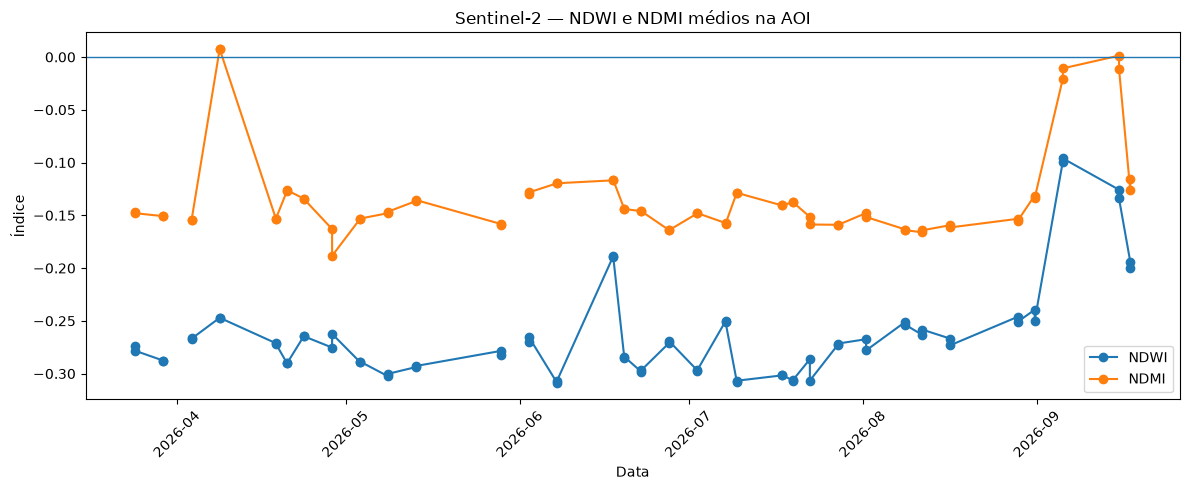

In [29]:
if not df_s2.empty:

    display(
        df_s2[
            [
                "NDWI_mean",
                "NDMI_mean",
                "NDWI_positive_fraction",
                "cloud_pct_scene",
                "valid_pixels"
            ]
        ]
        .describe()
        .T
    )

    plt.figure(
        figsize=(12, 5)
    )

    plt.plot(
        df_s2["date"],
        df_s2["NDWI_mean"],
        marker="o",
        label="NDWI"
    )

    plt.plot(
        df_s2["date"],
        df_s2["NDMI_mean"],
        marker="o",
        label="NDMI"
    )

    plt.axhline(
        0,
        linewidth=1
    )

    plt.title(
        "Sentinel-2 — NDWI e NDMI médios na AOI"
    )
    plt.xlabel("Data")
    plt.ylabel("Índice")
    plt.legend()
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

## 6.3 — Água superficial histórica: JRC Global Surface Water

Agora adicionamos uma fonte independente do Sentinel-2 recente.

Coleção:

```text
JRC/GSW1_4/GlobalSurfaceWater
```

Features:

- ocorrência histórica de água;
- sazonalidade;
- recorrência;
- distância aproximada até água detectada historicamente.

A distância calculada abaixo é limitada pela janela do `fastDistanceTransform`.

Ela deve ser interpretada como contexto espacial, não como confirmação de inundação atual.

In [30]:
gsw = ee.Image(
    "JRC/GSW1_4/GlobalSurfaceWater"
)

water_any = (
    gsw.select(
        "max_extent"
    )
    .unmask(0)
    .eq(1)
)

water_recurrent_50 = (
    gsw.select(
        "occurrence"
    )
    .unmask(0)
    .gte(50)
)

# 512 pixels * ~30 m = ~15,36 km de busca máxima.
DISTANCE_NEIGHBORHOOD_PIXELS = 512
JRC_SCALE_M = 30

distance_any_water_m = (
    water_any
    .fastDistanceTransform(
        neighborhood=DISTANCE_NEIGHBORHOOD_PIXELS
    )
    .sqrt()
    .multiply(JRC_SCALE_M)
    .rename(
        "distance_any_water_m"
    )
)

distance_recurrent_water_m = (
    water_recurrent_50
    .fastDistanceTransform(
        neighborhood=DISTANCE_NEIGHBORHOOD_PIXELS
    )
    .sqrt()
    .multiply(JRC_SCALE_M)
    .rename(
        "distance_recurrent_water_m"
    )
)

jrc_context_image = (
    gsw.select(
        [
            "occurrence",
            "seasonality",
            "recurrence"
        ]
    )
    .addBands(
        distance_any_water_m
    )
    .addBands(
        distance_recurrent_water_m
    )
)

In [31]:
jrc_stats = jrc_context_image.reduceRegion(
    reducer=(
        ee.Reducer.mean()
        .combine(
            reducer2=ee.Reducer.min(),
            sharedInputs=True
        )
        .combine(
            reducer2=ee.Reducer.max(),
            sharedInputs=True
        )
    ),
    geometry=AOI,
    scale=JRC_SCALE_M,
    bestEffort=True,
    maxPixels=10_000_000,
).getInfo()

jrc_features = {
    "water_occurrence_mean_pct": jrc_stats.get(
        "occurrence_mean"
    ),
    "water_occurrence_max_pct": jrc_stats.get(
        "occurrence_max"
    ),
    "water_seasonality_mean_months": jrc_stats.get(
        "seasonality_mean"
    ),
    "water_recurrence_mean_pct": jrc_stats.get(
        "recurrence_mean"
    ),
    "distance_any_water_min_m": jrc_stats.get(
        "distance_any_water_m_min"
    ),
    "distance_recurrent_water_min_m": jrc_stats.get(
        "distance_recurrent_water_m_min"
    ),
}

pd.DataFrame(
    [jrc_features]
).T.rename(
    columns={
        0: "valor"
    }
)

,valor
water_occurrence_mean_pct,None
water_occurrence_max_pct,None
water_seasonality_mean_months,None
water_recurrence_mean_pct,None
distance_any_water_min_m,417.8516
distance_recurrent_water_min_m,2983.9068


In [32]:
Map_water = geemap.Map(
    center=[
        LATITUDE,
        LONGITUDE
    ],
    zoom=13
)

Map_water.addLayer(
    gsw.select(
        "occurrence"
    ),
    {
        "min": 0,
        "max": 100,
    },
    "JRC Water Occurrence"
)

Map_water.addLayer(
    AOI,
    {},
    "AOI"
)

Map_water

Map(center=[-21.1775, -47.81028], controls=(WidgetControl(options=['position', 'transparent_bg'], position='to…

# FASE 7 — SRTM: elevação, declividade e posição relativa

Nesta fase adicionamos contexto topográfico.

## Por que isso importa?

A mesma quantidade de chuva pode produzir respostas diferentes em:

- uma baixada;
- uma área praticamente plana;
- uma encosta;
- um topo;
- uma área cercada por relevo mais alto.

Não vamos afirmar que "baixo = alagado".

Vamos transformar topografia em features mensuráveis.

In [33]:
SRTM = (
    ee.Image(
        "USGS/SRTMGL1_003"
    )
    .select(
        "elevation"
    )
)

SLOPE = (
    ee.Terrain.slope(
        SRTM
    )
    .rename(
        "slope_deg"
    )
)

TOPO_NEIGHBORHOOD_M = 1000

AOI_TOPO_CONTEXT = (
    PONTO_FAZENDA
    .buffer(
        TOPO_NEIGHBORHOOD_M
    )
)

In [34]:
# Estatísticas dentro da AOI principal.

topo_aoi_stats = (
    SRTM
    .rename(
        "elevation"
    )
    .addBands(
        SLOPE
    )
    .reduceRegion(
        reducer=(
            ee.Reducer.mean()
            .combine(
                reducer2=ee.Reducer.minMax(),
                sharedInputs=True
            )
        ),
        geometry=AOI,
        scale=30,
        bestEffort=True,
        maxPixels=10_000_000,
    )
    .getInfo()
)

# Contexto em 1 km ao redor.
topo_1km_stats = (
    SRTM
    .rename(
        "elevation"
    )
    .addBands(
        SLOPE
    )
    .reduceRegion(
        reducer=(
            ee.Reducer.mean()
            .combine(
                reducer2=ee.Reducer.minMax(),
                sharedInputs=True
            )
        ),
        geometry=AOI_TOPO_CONTEXT,
        scale=30,
        bestEffort=True,
        maxPixels=10_000_000,
    )
    .getInfo()
)


topografia_features = {
    "elevation_aoi_mean_m": topo_aoi_stats.get(
        "elevation_mean"
    ),
    "elevation_aoi_min_m": topo_aoi_stats.get(
        "elevation_min"
    ),
    "elevation_aoi_max_m": topo_aoi_stats.get(
        "elevation_max"
    ),
    "slope_aoi_mean_deg": topo_aoi_stats.get(
        "slope_deg_mean"
    ),
    "slope_aoi_max_deg": topo_aoi_stats.get(
        "slope_deg_max"
    ),

    "elevation_1km_mean_m": topo_1km_stats.get(
        "elevation_mean"
    ),
    "elevation_1km_min_m": topo_1km_stats.get(
        "elevation_min"
    ),
    "elevation_1km_max_m": topo_1km_stats.get(
        "elevation_max"
    ),
    "slope_1km_mean_deg": topo_1km_stats.get(
        "slope_deg_mean"
    ),
}


if (
    topografia_features[
        "elevation_aoi_mean_m"
    ] is not None
    and topografia_features[
        "elevation_1km_mean_m"
    ] is not None
):
    topografia_features[
        "relative_elevation_aoi_vs_1km_m"
    ] = (
        topografia_features[
            "elevation_aoi_mean_m"
        ]
        - topografia_features[
            "elevation_1km_mean_m"
        ]
    )


if (
    topografia_features[
        "elevation_1km_max_m"
    ] is not None
    and topografia_features[
        "elevation_1km_min_m"
    ] is not None
):
    topografia_features[
        "local_relief_1km_m"
    ] = (
        topografia_features[
            "elevation_1km_max_m"
        ]
        - topografia_features[
            "elevation_1km_min_m"
        ]
    )


pd.DataFrame(
    [topografia_features]
).T.rename(
    columns={
        0: "valor"
    }
)

,valor
elevation_aoi_mean_m,549.6944
elevation_aoi_min_m,524.0000
elevation_aoi_max_m,587.0000
slope_aoi_mean_deg,4.8789
slope_aoi_max_deg,17.3535
elevation_1km_mean_m,546.0914
elevation_1km_min_m,523.0000
elevation_1km_max_m,587.0000
slope_1km_mean_deg,4.3523
relative_elevation_aoi_vs_1km_m,3.6030


In [35]:
Map_topo = geemap.Map(
    center=[
        LATITUDE,
        LONGITUDE
    ],
    zoom=13
)

Map_topo.addLayer(
    SRTM,
    {
        "min": topografia_features.get(
            "elevation_1km_min_m",
            0
        ),
        "max": topografia_features.get(
            "elevation_1km_max_m",
            1000
        ),
    },
    "Elevação SRTM"
)

Map_topo.addLayer(
    SLOPE,
    {
        "min": 0,
        "max": 30,
    },
    "Declividade"
)

Map_topo.addLayer(
    AOI,
    {},
    "AOI"
)

Map_topo

Map(center=[-21.1775, -47.81028], controls=(WidgetControl(options=['position', 'transparent_bg'], position='to…

# FASE 8 — SoilGrids: textura e propriedades do solo

O SoilGrids adiciona uma dimensão relativamente estática do terreno.

## 8.1 — Propriedades iniciais

- argila;
- areia;
- silte;
- densidade aparente;
- carbono orgânico.

Os assets atuais no Earth Engine possuem seis bandas de profundidade.

Para tráfego agrícola começaremos pelas camadas:

- 0–5 cm;
- 5–15 cm.

## 8.2 — Conversões

Conforme a documentação do SoilGrids:

- `clay`, `sand`, `silt`: dividir por 10 → %
- `bdod`: dividir por 100 → kg/dm³
- `soc`: dividir por 10 → g/kg

## 8.3 — Limitação

SoilGrids é uma predição global em grade, não uma análise laboratorial da fazenda.

Logo, a feature deve ser tratada como contexto espacial estimado.

In [36]:
SOILGRIDS_CONFIG = {
    "clay_pct": {
        "asset": "clay_mean",
        "divisor": 10.0,
    },
    "sand_pct": {
        "asset": "sand_mean",
        "divisor": 10.0,
    },
    "silt_pct": {
        "asset": "silt_mean",
        "divisor": 10.0,
    },
    "bulk_density_kg_dm3": {
        "asset": "bdod_mean",
        "divisor": 100.0,
    },
    "soc_g_kg": {
        "asset": "soc_mean",
        "divisor": 10.0,
    },
}


def selecionar_bandas_superficiais(
    band_names
):
    desejadas = []

    for nome in band_names:
        if (
            "0-5cm" in nome
            or "5-15cm" in nome
        ):
            desejadas.append(
                nome
            )

    # Fallback para não quebrar se o nome do asset mudar,
    # mas a ordem continuar sendo por profundidade.
    if len(desejadas) < 2:
        desejadas = band_names[:2]

    return desejadas


def extrair_soilgrids(
    aoi
):
    resultado = {}
    inventario = []

    for feature_name, config in SOILGRIDS_CONFIG.items():

        asset_id = (
            "projects/soilgrids-isric/"
            + config["asset"]
        )

        imagem = ee.Image(
            asset_id
        )

        bandas = imagem.bandNames().getInfo()

        selecionadas = selecionar_bandas_superficiais(
            bandas
        )

        inventario.append(
            {
                "feature": feature_name,
                "asset": asset_id,
                "bandas_disponiveis": bandas,
                "bandas_usadas": selecionadas,
            }
        )

        stats = (
            imagem
            .select(
                selecionadas
            )
            .reduceRegion(
                reducer=ee.Reducer.mean(),
                geometry=aoi,
                scale=250,
                bestEffort=True,
                maxPixels=10_000_000,
            )
            .getInfo()
        )

        for banda, valor in stats.items():

            chave = (
                f"{feature_name}__{banda}"
            )

            if valor is None:
                resultado[chave] = np.nan
            else:
                resultado[chave] = (
                    float(valor)
                    / config["divisor"]
                )

    return (
        resultado,
        pd.DataFrame(inventario)
    )


soilgrids_features, soilgrids_inventory = (
    extrair_soilgrids(
        AOI
    )
)

display(
    soilgrids_inventory
)

display(
    pd.DataFrame(
        [soilgrids_features]
    )
    .T
    .rename(
        columns={
            0: "valor"
        }
    )
)

,feature,asset,bandas_disponiveis,bandas_usadas
0,clay_pct,projects/soilgrids-isric/clay_mean,"[clay_0-5cm_mean, clay_5-15cm_mean, clay_15-30...","[clay_0-5cm_mean, clay_5-15cm_mean]"
1,sand_pct,projects/soilgrids-isric/sand_mean,"[sand_0-5cm_mean, sand_5-15cm_mean, sand_15-30...","[sand_0-5cm_mean, sand_5-15cm_mean]"
2,silt_pct,projects/soilgrids-isric/silt_mean,"[silt_0-5cm_mean, silt_5-15cm_mean, silt_15-30...","[silt_0-5cm_mean, silt_5-15cm_mean]"
3,bulk_density_kg_dm3,projects/soilgrids-isric/bdod_mean,"[bdod_0-5cm_mean, bdod_5-15cm_mean, bdod_15-30...","[bdod_0-5cm_mean, bdod_5-15cm_mean]"
4,soc_g_kg,projects/soilgrids-isric/soc_mean,"[soc_0-5cm_mean, soc_5-15cm_mean, soc_15-30cm_...","[soc_0-5cm_mean, soc_5-15cm_mean]"


,valor
clay_pct__clay_0-5cm_mean,NaN
clay_pct__clay_5-15cm_mean,NaN
sand_pct__sand_0-5cm_mean,NaN
sand_pct__sand_5-15cm_mean,NaN
silt_pct__silt_0-5cm_mean,NaN
silt_pct__silt_5-15cm_mean,NaN
bulk_density_kg_dm3__bdod_0-5cm_mean,NaN
bulk_density_kg_dm3__bdod_5-15cm_mean,NaN
soc_g_kg__soc_0-5cm_mean,NaN
soc_g_kg__soc_5-15cm_mean,NaN


## 8.4 — Verificação de consistência da textura

Para cada profundidade, a soma:

```text
argila + areia + silte
```

deve ficar aproximadamente em torno de 100%.

Pequenas diferenças podem existir por arredondamento/modelagem.

In [37]:
soil_texture_check = []

profundidades_detectadas = set()

for coluna in soilgrids_features:
    if "0-5cm" in coluna:
        profundidades_detectadas.add(
            "0-5cm"
        )
    if "5-15cm" in coluna:
        profundidades_detectadas.add(
            "5-15cm"
        )


for profundidade in sorted(
    profundidades_detectadas
):

    valores = {}

    for textura in [
        "clay_pct",
        "sand_pct",
        "silt_pct",
    ]:
        encontrados = [
            valor
            for chave, valor
            in soilgrids_features.items()
            if (
                chave.startswith(
                    textura
                )
                and profundidade in chave
            )
        ]

        valores[textura] = (
            encontrados[0]
            if encontrados
            else np.nan
        )

    soma = np.nansum(
        list(
            valores.values()
        )
    )

    soil_texture_check.append(
        {
            "profundidade": profundidade,
            **valores,
            "soma_pct": soma,
        }
    )


pd.DataFrame(
    soil_texture_check
)

,profundidade,clay_pct,sand_pct,silt_pct,soma_pct
0,0-5cm,NaN,NaN,NaN,0.0000
1,5-15cm,NaN,NaN,NaN,0.0000


# FASE 9 — Open-Meteo: chuva antecedente e umidade de reanálise

O satélite observa o terreno em datas específicas.

Para explicar o contexto anterior a cada passagem, precisamos saber o que aconteceu nos dias anteriores.

## Features dinâmicas

- precipitação diária;
- chuva acumulada em 3 dias;
- chuva acumulada em 7 dias;
- chuva acumulada em 14 dias;
- dias desde chuva relevante;
- umidade média do solo 0–7 cm de reanálise/modelagem.

## Interpretação correta

A umidade do Open-Meteo não é uma medição feita dentro do talhão.

Ela serve como referência meteorológica espacialmente mais grosseira para cruzar com o radar.

In [38]:
OPEN_METEO_ARCHIVE_URL = (
    "https://archive-api.open-meteo.com/v1/archive"
)


def buscar_open_meteo_historico(
    latitude,
    longitude,
    data_inicio,
    data_fim,
    timeout=40
):
    params = {
        "latitude": latitude,
        "longitude": longitude,
        "start_date": data_inicio,
        "end_date": data_fim,
        "daily": ",".join(
            [
                "precipitation_sum",
                "et0_fao_evapotranspiration",
            ]
        ),
        "hourly": ",".join(
            [
                "soil_moisture_0_to_7cm",
            ]
        ),
        "timezone": "auto",
    }

    resposta = requests.get(
        OPEN_METEO_ARCHIVE_URL,
        params=params,
        timeout=timeout,
    )

    resposta.raise_for_status()

    return resposta.json()


clima_json = buscar_open_meteo_historico(
    LATITUDE,
    LONGITUDE,
    DATA_INICIO_STR,
    DATA_FIM_STR
)

print(
    "Timezone:",
    clima_json.get(
        "timezone"
    )
)

print(
    "Elevação do grid meteorológico:",
    clima_json.get(
        "elevation"
    )
)

Timezone: America/Sao_Paulo
Elevação do grid meteorológico: 547.0


In [39]:
# ============================================================
# DADOS DIÁRIOS
# ============================================================

daily = clima_json.get(
    "daily",
    {}
)

df_daily = pd.DataFrame(
    {
        "date": pd.to_datetime(
            daily.get(
                "time",
                []
            )
        ),
        "precipitation_mm": pd.to_numeric(
            pd.Series(
                daily.get(
                    "precipitation_sum",
                    []
                )
            ),
            errors="coerce"
        ),
        "et0_mm": pd.to_numeric(
            pd.Series(
                daily.get(
                    "et0_fao_evapotranspiration",
                    []
                )
            ),
            errors="coerce"
        ),
    }
)

df_daily = (
    df_daily
    .sort_values("date")
    .reset_index(drop=True)
)


for janela in [
    3,
    7,
    14
]:
    df_daily[
        f"rain_{janela}d_mm"
    ] = (
        df_daily[
            "precipitation_mm"
        ]
        .rolling(
            window=janela,
            min_periods=1
        )
        .sum()
    )


# Chuva >= 1 mm usada apenas para calcular recência.
evento_chuva = (
    df_daily[
        "precipitation_mm"
    ]
    >= 1.0
)

ultima_data_chuva = (
    df_daily["date"]
    .where(
        evento_chuva
    )
    .ffill()
)

df_daily[
    "days_since_rain_ge_1mm"
] = (
    df_daily["date"]
    - ultima_data_chuva
).dt.days


df_daily.head()

,date,precipitation_mm,et0_mm,rain_3d_mm,rain_7d_mm,rain_14d_mm,days_since_rain_ge_1mm
0,2026-03-22,0.0000,4.8800,0.0000,0.0000,0.0000,NaN
1,2026-03-23,1.2000,4.9100,1.2000,1.2000,1.2000,0.0000
2,2026-03-24,1.3000,5.2600,2.5000,2.5000,2.5000,0.0000
3,2026-03-25,7.1000,3.5200,9.6000,9.6000,9.6000,0.0000
4,2026-03-26,4.2000,3.9500,12.6000,13.8000,13.8000,0.0000


In [40]:
# ============================================================
# UMIDADE HORÁRIA DO SOLO -> MÉDIA DIÁRIA
# ============================================================

hourly = clima_json.get(
    "hourly",
    {}
)

df_soil_hourly = pd.DataFrame(
    {
        "datetime": pd.to_datetime(
            hourly.get(
                "time",
                []
            )
        ),
        "soil_moisture_0_7cm_m3_m3": pd.to_numeric(
            pd.Series(
                hourly.get(
                    "soil_moisture_0_to_7cm",
                    []
                )
            ),
            errors="coerce"
        ),
    }
)


if not df_soil_hourly.empty:

    df_soil_hourly[
        "date"
    ] = (
        df_soil_hourly[
            "datetime"
        ]
        .dt
        .normalize()
    )

    df_soil_daily = (
        df_soil_hourly
        .groupby(
            "date",
            as_index=False
        )
        .agg(
            soil_moisture_0_7cm_mean_m3_m3=(
                "soil_moisture_0_7cm_m3_m3",
                "mean"
            ),
            soil_moisture_0_7cm_min_m3_m3=(
                "soil_moisture_0_7cm_m3_m3",
                "min"
            ),
            soil_moisture_0_7cm_max_m3_m3=(
                "soil_moisture_0_7cm_m3_m3",
                "max"
            ),
        )
    )

else:
    df_soil_daily = pd.DataFrame(
        columns=[
            "date",
            "soil_moisture_0_7cm_mean_m3_m3",
            "soil_moisture_0_7cm_min_m3_m3",
            "soil_moisture_0_7cm_max_m3_m3",
        ]
    )


df_clima = df_daily.merge(
    df_soil_daily,
    on="date",
    how="left"
)


if (
    "soil_moisture_0_7cm_mean_m3_m3"
    in df_clima.columns
):
    mediana_umidade = (
        df_clima[
            "soil_moisture_0_7cm_mean_m3_m3"
        ]
        .median()
    )

    df_clima[
        "soil_moisture_anomaly_m3_m3"
    ] = (
        df_clima[
            "soil_moisture_0_7cm_mean_m3_m3"
        ]
        - mediana_umidade
    )


df_clima.tail(15)

,date,precipitation_mm,et0_mm,rain_3d_mm,rain_7d_mm,rain_14d_mm,days_since_rain_ge_1mm,soil_moisture_0_7cm_mean_m3_m3,soil_moisture_0_7cm_min_m3_m3,soil_moisture_0_7cm_max_m3_m3,soil_moisture_anomaly_m3_m3
166,2026-09-04,0.0000,4.9100,0.9000,17.1000,19.2000,3.0000,0.2239,0.1970,0.2460,0.0169
167,2026-09-05,5.8000,3.7300,5.8000,22.9000,25.0000,0.0000,0.2442,0.2080,0.3110,0.0372
168,2026-09-06,4.9000,2.2900,10.7000,27.7000,29.9000,0.0000,0.3395,0.3140,0.3600,0.1325
169,2026-09-07,6.4000,2.6500,17.1000,33.3000,36.3000,0.0000,0.3932,0.3480,0.4340,0.1862
170,2026-09-08,7.5000,2.5600,18.8000,25.5000,43.8000,0.0000,0.4297,0.3870,0.4970,0.2227
171,2026-09-09,6.0000,2.8900,19.9000,30.6000,47.7000,0.0000,0.4717,0.4470,0.5100,0.2647
172,2026-09-10,14.4000,2.7000,27.9000,45.0000,62.1000,0.0000,0.4705,0.4550,0.5380,0.2635
173,2026-09-11,1.4000,3.7900,21.8000,46.4000,63.5000,0.0000,0.4579,0.4280,0.4990,0.2509
174,2026-09-12,2.8000,4.0400,18.6000,43.4000,66.3000,0.0000,0.4317,0.4060,0.4700,0.2247
175,2026-09-13,0.7000,4.3700,4.9000,39.2000,66.9000,1.0000,0.4074,0.3880,0.4250,0.2004


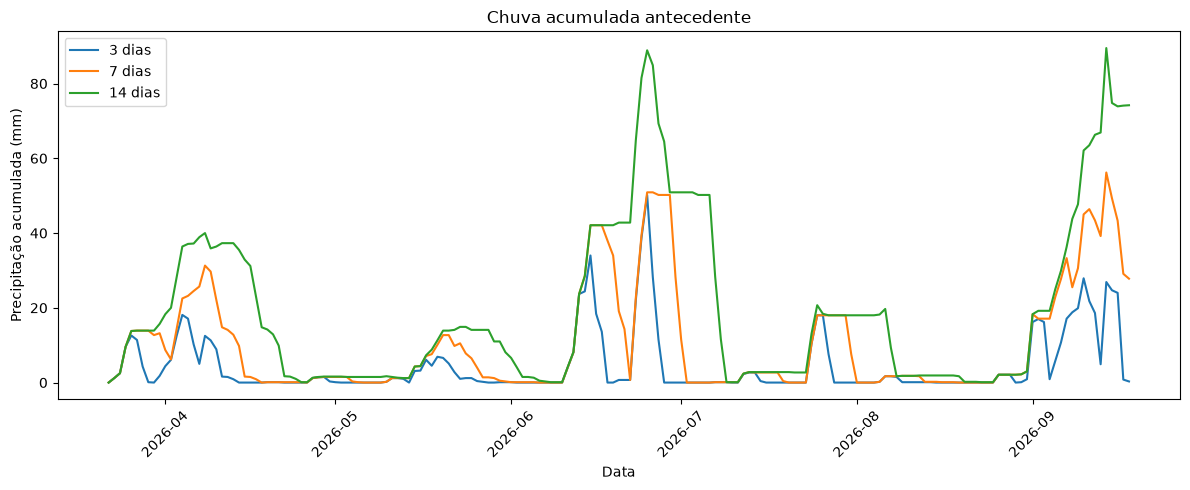

In [41]:
if not df_clima.empty:

    plt.figure(
        figsize=(12, 5)
    )

    plt.plot(
        df_clima["date"],
        df_clima["rain_3d_mm"],
        label="3 dias"
    )

    plt.plot(
        df_clima["date"],
        df_clima["rain_7d_mm"],
        label="7 dias"
    )

    plt.plot(
        df_clima["date"],
        df_clima["rain_14d_mm"],
        label="14 dias"
    )

    plt.title(
        "Chuva acumulada antecedente"
    )
    plt.xlabel("Data")
    plt.ylabel("Precipitação acumulada (mm)")
    plt.legend()
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

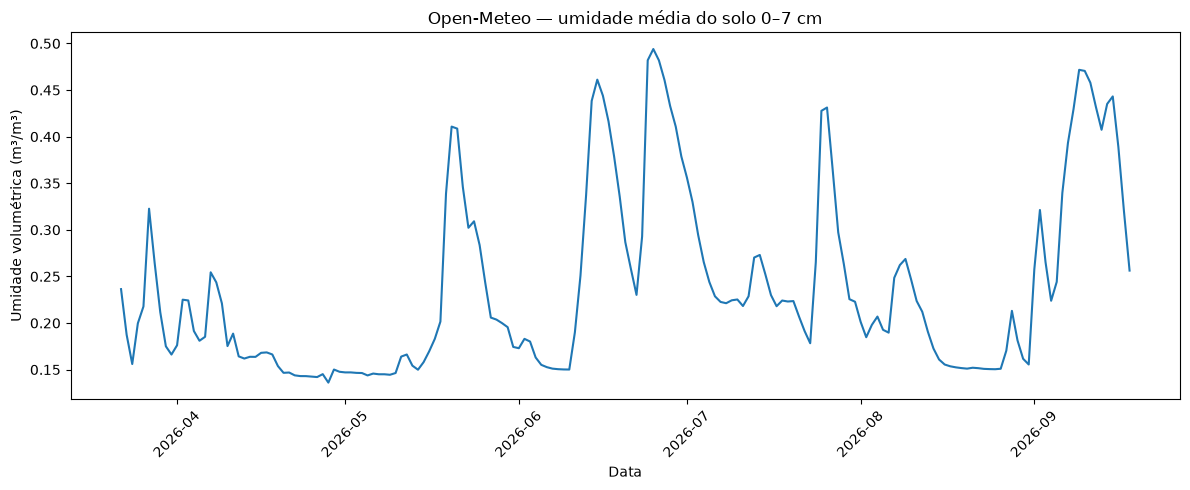

In [42]:
if (
    "soil_moisture_0_7cm_mean_m3_m3"
    in df_clima.columns
    and df_clima[
        "soil_moisture_0_7cm_mean_m3_m3"
    ].notna().any()
):

    plt.figure(
        figsize=(12, 5)
    )

    plt.plot(
        df_clima["date"],
        df_clima[
            "soil_moisture_0_7cm_mean_m3_m3"
        ]
    )

    plt.title(
        "Open-Meteo — umidade média do solo 0–7 cm"
    )
    plt.xlabel("Data")
    plt.ylabel("Umidade volumétrica (m³/m³)")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

# FASE 10 — Integração ambiental, EDA multivariado e handoff

Agora reunimos as fontes sem misturar suas naturezas.

## Estrutura conceitual

### Dinâmicas

Mudam com o tempo:

- Sentinel-1;
- Sentinel-2;
- chuva;
- umidade de reanálise.

### Estáticas ou quase estáticas

Mudam muito pouco para a mesma fazenda:

- relevo;
- textura do solo;
- proximidade histórica de água.

## Eixo temporal

A tabela será construída a partir das observações Sentinel-1.

Para cada passagem SAR:

1. juntamos o clima do mesmo dia;
2. buscamos a observação Sentinel-2 válida mais próxima;
3. anexamos os atributos estáticos do local.

Assim não inventamos imagens ópticas para datas em que havia nuvem ou não houve passagem.

In [43]:
S2_TOLERANCIA_DIAS = 5


def integrar_fontes_ambientais(
    df_s1,
    df_s2,
    df_clima,
    jrc_features,
    topografia_features,
    soilgrids_features,
    tolerancia_s2_dias=5
):
    if df_s1.empty:
        raise ValueError(
            "A série Sentinel-1 está vazia."
        )

    base = df_s1.copy()

    base[
        "date_day"
    ] = (
        base["date"]
        .dt
        .normalize()
    )

    # ----------------------------
    # Clima do mesmo dia.
    # ----------------------------

    clima = df_clima.copy()

    clima[
        "date_day"
    ] = (
        pd.to_datetime(
            clima["date"]
        )
        .dt
        .normalize()
    )

    clima = clima.drop(
        columns=[
            "date"
        ],
        errors="ignore"
    )

    base = base.merge(
        clima,
        on="date_day",
        how="left",
    )

    # ----------------------------
    # Sentinel-2 mais próximo.
    # ----------------------------

    if not df_s2.empty:

        optico = df_s2.copy()

        optico = optico.rename(
            columns={
                "date": "s2_date"
            }
        )

        base = base.sort_values(
            "date"
        )

        optico = optico.sort_values(
            "s2_date"
        )

        base = pd.merge_asof(
            base,
            optico,
            left_on="date",
            right_on="s2_date",
            direction="nearest",
            tolerance=pd.Timedelta(
                days=tolerancia_s2_dias
            ),
            suffixes=(
                "_s1",
                "_s2"
            ),
        )

        base[
            "s2_time_distance_days"
        ] = (
            (
                base["date"]
                - base["s2_date"]
            )
            .abs()
            .dt
            .total_seconds()
            / 86400
        )

    # ----------------------------
    # Features estáticas.
    # ----------------------------

    for chave, valor in jrc_features.items():
        base[
            f"jrc__{chave}"
        ] = valor

    for chave, valor in topografia_features.items():
        base[
            f"topo__{chave}"
        ] = valor

    for chave, valor in soilgrids_features.items():
        base[
            f"soil__{chave}"
        ] = valor

    base[
        "farm_latitude"
    ] = LATITUDE

    base[
        "farm_longitude"
    ] = LONGITUDE

    base[
        "aoi_buffer_m"
    ] = AOI_BUFFER_M

    base[
        "location_precise"
    ] = LOCALIZACAO_PRECISA

    return (
        base
        .sort_values("date")
        .reset_index(drop=True)
    )


df_ambiental = integrar_fontes_ambientais(
    df_s1=df_s1,
    df_s2=df_s2,
    df_clima=df_clima,
    jrc_features=jrc_features,
    topografia_features=topografia_features,
    soilgrids_features=soilgrids_features,
    tolerancia_s2_dias=S2_TOLERANCIA_DIAS,
)

print(
    "Linhas:",
    len(df_ambiental)
)

print(
    "Colunas:",
    df_ambiental.shape[1]
)

display(
    df_ambiental.head()
)

Linhas: 35
Colunas: 70


,VH_mean_db,VH_median_db,VH_std_db,VV_mean_db,VV_median_db,VV_minus_VH_mean_db,VV_std_db,angle_mean_deg,date,orbit_pass,platform,relative_orbit,valid_pixels_s1,VV_baseline_median_db,VH_baseline_median_db,VV_anomaly_db,VH_anomaly_db,date_day,precipitation_mm,et0_mm,rain_3d_mm,rain_7d_mm,rain_14d_mm,days_since_rain_ge_1mm,soil_moisture_0_7cm_mean_m3_m3,soil_moisture_0_7cm_min_m3_m3,soil_moisture_0_7cm_max_m3_m3,soil_moisture_anomaly_m3_m3,NDMI_mean,NDMI_median,NDMI_std,NDWI_mean,NDWI_median,NDWI_positive_fraction,NDWI_std,cloud_pct_scene,s2_date,valid_pixels_s2,s2_time_distance_days,jrc__water_occurrence_mean_pct,jrc__water_occurrence_max_pct,jrc__water_seasonality_mean_months,jrc__water_recurrence_mean_pct,jrc__distance_any_water_min_m,jrc__distance_recurrent_water_min_m,topo__elevation_aoi_mean_m,topo__elevation_aoi_min_m,topo__elevation_aoi_max_m,topo__slope_aoi_mean_deg,topo__slope_aoi_max_deg,topo__elevation_1km_mean_m,topo__elevation_1km_min_m,topo__elevation_1km_max_m,topo__slope_1km_mean_deg,topo__relative_elevation_aoi_vs_1km_m,topo__local_relief_1km_m,soil__clay_pct__clay_0-5cm_mean,soil__clay_pct__clay_5-15cm_mean,soil__sand_pct__sand_0-5cm_mean,soil__sand_pct__sand_5-15cm_mean,soil__silt_pct__silt_0-5cm_mean,soil__silt_pct__silt_5-15cm_mean,soil__bulk_density_kg_dm3__bdod_0-5cm_mean,soil__bulk_density_kg_dm3__bdod_5-15cm_mean,soil__soc_g_kg__soc_0-5cm_mean,soil__soc_g_kg__soc_5-15cm_mean,farm_latitude,farm_longitude,aoi_buffer_m,location_precise
0,-10.4946,-10.6855,4.2270,-5.9233,-6.1866,4.5713,3.9558,40.7863,2026-03-27 08:37:33,DESCENDING,C,126,7928,-5.6714,-10.3721,-0.2519,-0.1225,2026-03-27,0.1000,4.7800,11.4000,13.9000,13.9000,1.0000,0.3227,0.2900,0.3460,0.1157,-0.1508,-0.1779,0.1416,-0.2877,-0.2639,0.0083,0.1570,2.6933,2026-03-29 13:28:12,2031.0000,2.2018,None,None,None,None,417.8516,2983.9068,549.6944,524,587,4.8789,17.3535,546.0914,523,587,4.3523,3.6030,64,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-21.1775,-47.8103,500,False
1,-9.6005,-9.8817,4.3300,-4.6002,-4.8055,5.0002,4.0937,40.6361,2026-04-02 08:38:29,DESCENDING,A,126,7945,-5.6714,-10.3721,1.0712,0.7716,2026-04-02,1.7000,4.4900,6.1000,6.2000,20.0000,0.0000,0.2250,0.1920,0.2490,0.0180,-0.1545,-0.1820,0.1423,-0.2667,-0.2442,0.0098,0.1518,6.3188,2026-04-03 13:28:10,2028.0000,1.2012,None,None,None,None,417.8516,2983.9068,549.6944,524,587,4.8789,17.3535,546.0914,523,587,4.3523,3.6030,64,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-21.1775,-47.8103,500,False
2,-10.3203,-10.6917,4.3286,-5.6714,-5.9382,4.6488,3.9955,40.7829,2026-04-08 08:37:33,DESCENDING,C,126,7934,-5.6714,-10.3721,0.0000,0.0518,2026-04-08,8.2000,3.2000,12.5000,31.3000,40.0000,0.0000,0.2436,0.2200,0.2670,0.0366,0.0075,-0.0138,0.0928,-0.2471,-0.2362,0.0010,0.1073,68.0355,2026-04-08 13:28:09,2030.0000,0.2018,None,None,None,None,417.8516,2983.9068,549.6944,524,587,4.8789,17.3535,546.0914,523,587,4.3523,3.6030,64,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-21.1775,-47.8103,500,False
3,-10.4961,-10.6256,4.2619,-5.5087,-5.8141,4.9875,3.8742,40.6335,2026-04-14 08:38:29,DESCENDING,A,126,7944,-5.6714,-10.3721,0.1627,-0.1241,2026-04-14,0.0000,4.9200,0.0000,9.8000,35.5000,6.0000,0.1638,0.1540,0.1710,-0.0432,-0.1532,-0.1818,0.1384,-0.2712,-0.2488,0.0031,0.1455,1.2034,2026-04-18 13:28:11,2028.0000,4.2012,None,None,None,None,417.8516,2983.9068,549.6944,524,587,4.8789,17.3535,546.0914,523,587,4.3523,3.6030,64,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-21.1775,-47.8103,500,False
4,-10.2747,-10.5656,4.2078,-5.8466,-6.0609,4.4281,3.9426,40.6743,2026-04-20 08:37:50,DESCENDING,C,126,7942,-5.6714,-10.3721,-0.1752,0.0974,2026-04-20,0.0000,5.2200,0.1000,0.1000,12.9000,12.0000,0.1465,0.1440,0.1490,-0.0605,-0.1266,-0.1507,0.1442,-0.2904,-0.2674,0.0021,0.1477,0.6035,2026-04-20 13:28:29,2031.0000,0.2018,None,None,None,None,417.8516,2983.9068,549.6944,524,587,4.8789,17.3535,546.0914,523,587,4.3523,3.6030,64,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-21.1775,-47.8103,500,False


## 10.1 — Auditoria da tabela integrada

In [44]:
auditoria_ambiental = pd.DataFrame(
    {
        "variavel": df_ambiental.columns,

        "tipo": [
            str(
                df_ambiental[
                    coluna
                ].dtype
            )
            for coluna
            in df_ambiental.columns
        ],

        "ausentes": [
            int(
                df_ambiental[
                    coluna
                ]
                .isna()
                .sum()
            )
            for coluna
            in df_ambiental.columns
        ],

        "percentual_ausente": [
            float(
                df_ambiental[
                    coluna
                ]
                .isna()
                .mean()
                * 100
            )
            for coluna
            in df_ambiental.columns
        ],

        "unicos": [
            int(
                df_ambiental[
                    coluna
                ]
                .nunique(
                    dropna=True
                )
            )
            for coluna
            in df_ambiental.columns
        ],
    }
)

display(
    auditoria_ambiental.sort_values(
        "percentual_ausente",
        ascending=False
    )
)

,variavel,tipo,ausentes,percentual_ausente,unicos
61,soil__silt_pct__silt_5-15cm_mean,float64,35,100.0000,0
60,soil__silt_pct__silt_0-5cm_mean,float64,35,100.0000,0
56,soil__clay_pct__clay_0-5cm_mean,float64,35,100.0000,0
57,soil__clay_pct__clay_5-15cm_mean,float64,35,100.0000,0
65,soil__soc_g_kg__soc_5-15cm_mean,float64,35,100.0000,0
...,...,...,...,...,...
54,topo__relative_elevation_aoi_vs_1km_m,float64,0,0.0000,1
66,farm_latitude,float64,0,0.0000,1
67,farm_longitude,float64,0,0.0000,1
68,aoi_buffer_m,int64,0,0.0000,1


## 10.2 — Radar × chuva antecedente

Aqui procuramos associação temporal, não causalidade.

Se a relação não aparecer de forma forte, isso **não invalida** o Sentinel-1: vegetação, rugosidade e órbita também influenciam o sinal.

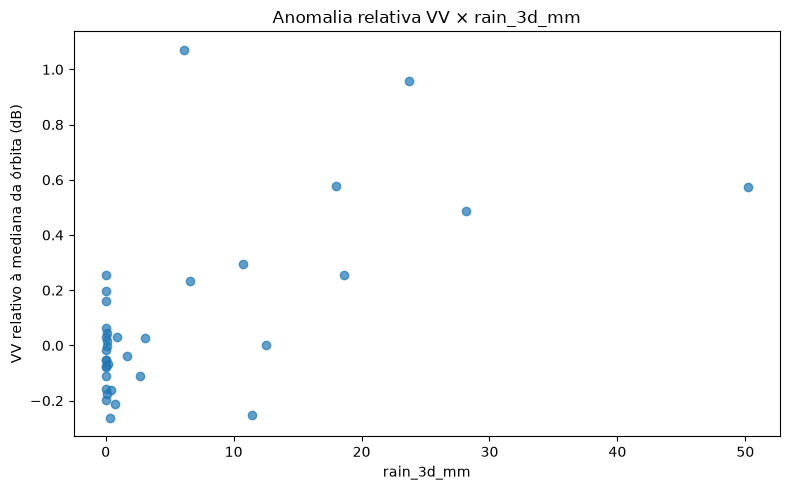

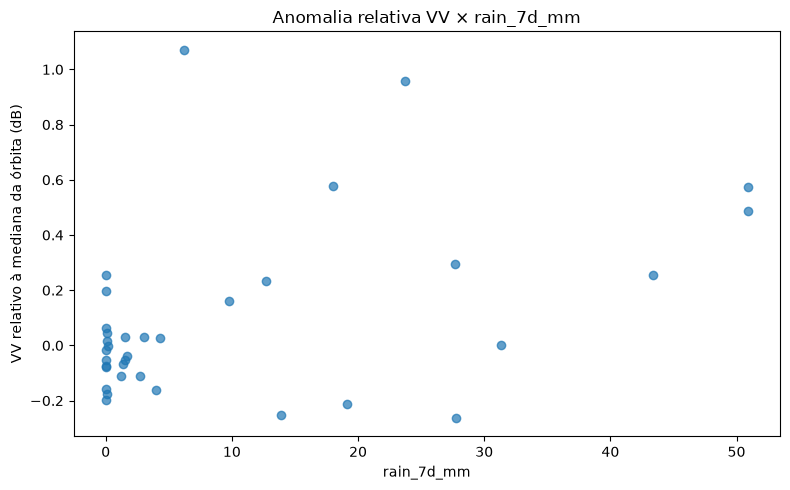

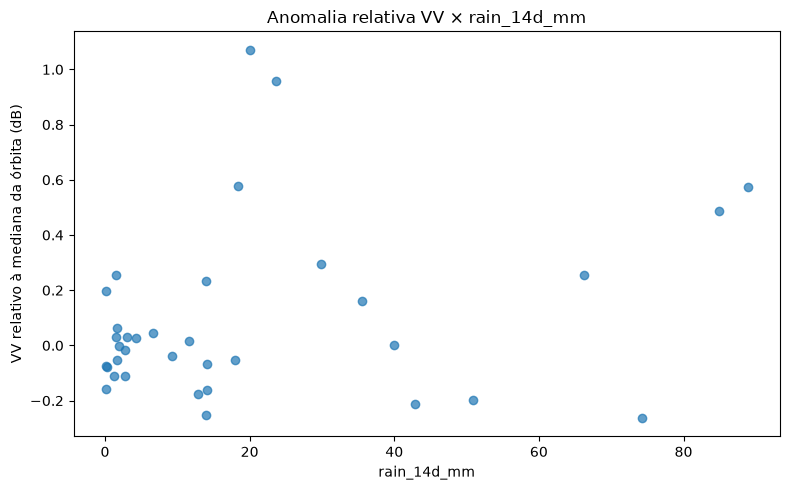

In [45]:
for coluna_chuva in [
    "rain_3d_mm",
    "rain_7d_mm",
    "rain_14d_mm",
]:

    if (
        coluna_chuva
        not in df_ambiental.columns
    ):
        continue

    dados = (
        df_ambiental[
            [
                coluna_chuva,
                "VV_anomaly_db",
                "VH_anomaly_db",
            ]
        ]
        .dropna()
    )

    if dados.empty:
        continue

    plt.figure(
        figsize=(8, 5)
    )

    plt.scatter(
        dados[
            coluna_chuva
        ],
        dados[
            "VV_anomaly_db"
        ],
        alpha=0.7
    )

    plt.title(
        f"Anomalia relativa VV × {coluna_chuva}"
    )
    plt.xlabel(
        coluna_chuva
    )
    plt.ylabel(
        "VV relativo à mediana da órbita (dB)"
    )
    plt.tight_layout()
    plt.show()

## 10.3 — Radar × umidade de reanálise

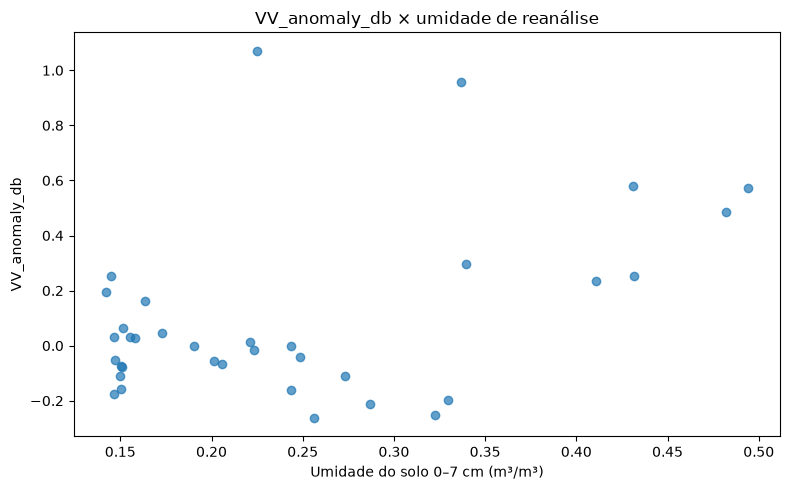

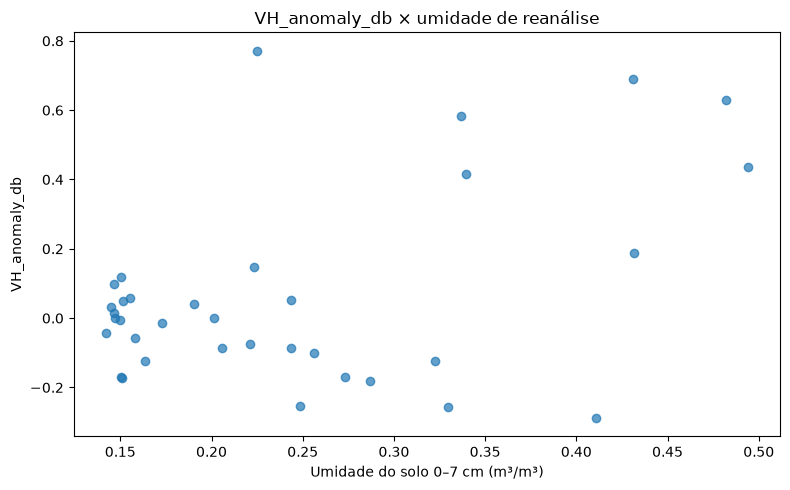

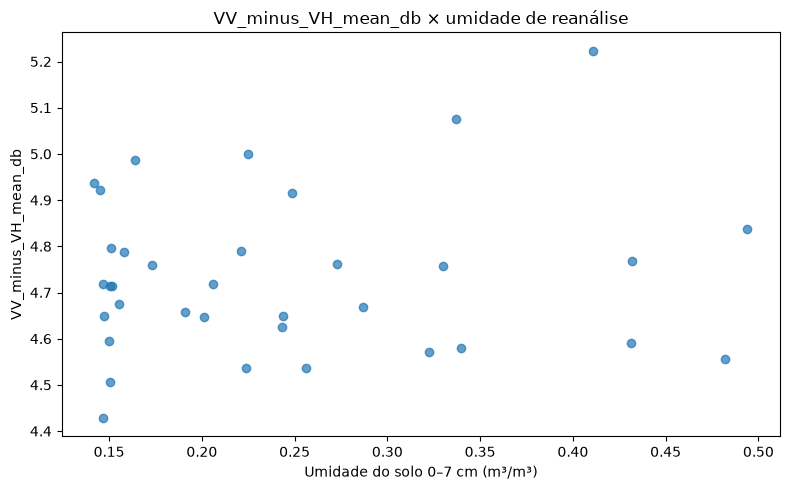

In [46]:
soil_moist_col = (
    "soil_moisture_0_7cm_mean_m3_m3"
)

if (
    soil_moist_col
    in df_ambiental.columns
):

    for sar_col in [
        "VV_anomaly_db",
        "VH_anomaly_db",
        "VV_minus_VH_mean_db",
    ]:

        dados = (
            df_ambiental[
                [
                    soil_moist_col,
                    sar_col
                ]
            ]
            .dropna()
        )

        if dados.empty:
            continue

        plt.figure(
            figsize=(8, 5)
        )

        plt.scatter(
            dados[
                soil_moist_col
            ],
            dados[
                sar_col
            ],
            alpha=0.7
        )

        plt.title(
            f"{sar_col} × umidade de reanálise"
        )
        plt.xlabel(
            "Umidade do solo 0–7 cm (m³/m³)"
        )
        plt.ylabel(
            sar_col
        )
        plt.tight_layout()
        plt.show()

## 10.4 — Sentinel-1 × Sentinel-2

O Sentinel-2 pode não ter observação em todas as passagens do Sentinel-1 por causa de:

- nuvem;
- frequência de revisita;
- filtragem de qualidade.

Por isso mantemos explicitamente:

```text
s2_time_distance_days
```

para o modelo saber o quão distante temporalmente estava a imagem óptica usada.

,VV_anomaly_db,VH_anomaly_db,NDWI_mean,NDMI_mean,s2_time_distance_days
VV_anomaly_db,1.0000,0.8773,0.3105,0.0220,0.2981
VH_anomaly_db,0.8773,1.0000,0.3518,0.1089,0.1443
NDWI_mean,0.3105,0.3518,1.0000,0.6617,0.2448
NDMI_mean,0.0220,0.1089,0.6617,1.0000,-0.0730
s2_time_distance_days,0.2981,0.1443,0.2448,-0.0730,1.0000


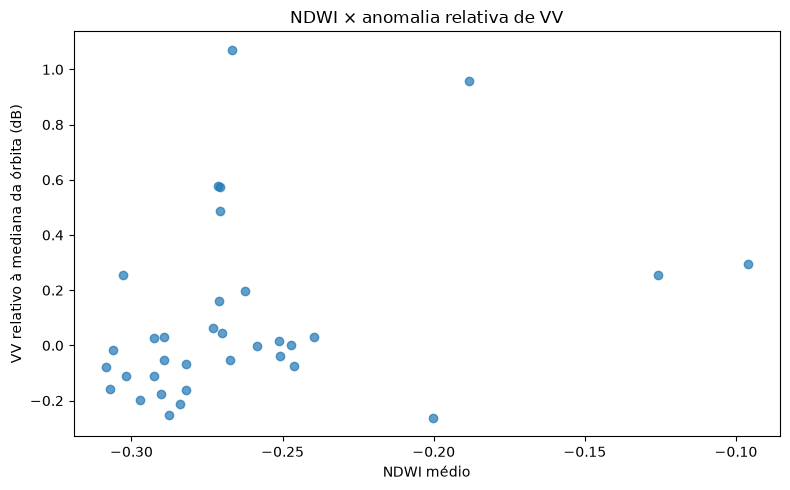

In [47]:
if (
    "NDWI_mean"
    in df_ambiental.columns
):

    dados = (
        df_ambiental[
            [
                "VV_anomaly_db",
                "VH_anomaly_db",
                "NDWI_mean",
                "NDMI_mean",
                "s2_time_distance_days",
            ]
        ]
        .dropna()
    )

    if not dados.empty:

        display(
            dados.corr()
        )

        plt.figure(
            figsize=(8, 5)
        )

        plt.scatter(
            dados["NDWI_mean"],
            dados["VV_anomaly_db"],
            alpha=0.7
        )

        plt.title(
            "NDWI × anomalia relativa de VV"
        )
        plt.xlabel(
            "NDWI médio"
        )
        plt.ylabel(
            "VV relativo à mediana da órbita (dB)"
        )
        plt.tight_layout()
        plt.show()

## 10.5 — Correlação das variáveis dinâmicas

Features estáticas de uma única fazenda ficam constantes no tempo.

Por isso não faz sentido avaliá-las em uma matriz de correlação temporal desta propriedade.

Argila, relevo e distância da água passam a ser estatisticamente úteis quando repetirmos o pipeline para **várias fazendas ou talhões**.

In [48]:
dynamic_candidates = [
    "VV_mean_db",
    "VH_mean_db",
    "VV_minus_VH_mean_db",
    "VV_anomaly_db",
    "VH_anomaly_db",
    "angle_mean_deg",

    "NDWI_mean",
    "NDMI_mean",
    "NDWI_positive_fraction",

    "precipitation_mm",
    "rain_3d_mm",
    "rain_7d_mm",
    "rain_14d_mm",
    "days_since_rain_ge_1mm",

    "soil_moisture_0_7cm_mean_m3_m3",
    "soil_moisture_anomaly_m3_m3",

    "et0_mm",
]

dynamic_features = [
    coluna
    for coluna in dynamic_candidates
    if coluna in df_ambiental.columns
]

correlacao_dinamica = (
    df_ambiental[
        dynamic_features
    ]
    .corr()
)

correlacao_dinamica

,VV_mean_db,VH_mean_db,VV_minus_VH_mean_db,VV_anomaly_db,VH_anomaly_db,angle_mean_deg,NDWI_mean,NDMI_mean,NDWI_positive_fraction,precipitation_mm,rain_3d_mm,rain_7d_mm,rain_14d_mm,days_since_rain_ge_1mm,soil_moisture_0_7cm_mean_m3_m3,soil_moisture_anomaly_m3_m3,et0_mm
VV_mean_db,1.0000,0.8352,0.4974,1.0000,0.8352,-0.0649,0.3105,0.0220,0.2637,0.5663,0.6071,0.4240,0.2490,-0.3773,0.4360,0.4360,-0.3153
VH_mean_db,0.8352,1.0000,-0.0617,0.8352,1.0000,0.1034,0.3518,0.1089,0.2883,0.4373,0.6277,0.5052,0.3223,-0.3468,0.4358,0.4358,-0.2191
VV_minus_VH_mean_db,0.4974,-0.0617,1.0000,0.4974,-0.0617,-0.2810,0.0240,-0.1468,0.0388,0.3378,0.1117,-0.0274,-0.0564,-0.1376,0.1038,0.1038,-0.2267
VV_anomaly_db,1.0000,0.8352,0.4974,1.0000,0.8352,-0.0649,0.3105,0.0220,0.2637,0.5663,0.6071,0.4240,0.2490,-0.3773,0.4360,0.4360,-0.3153
VH_anomaly_db,0.8352,1.0000,-0.0617,0.8352,1.0000,0.1034,0.3518,0.1089,0.2883,0.4373,0.6277,0.5052,0.3223,-0.3468,0.4358,0.4358,-0.2191
angle_mean_deg,-0.0649,0.1034,-0.2810,-0.0649,0.1034,1.0000,0.1581,0.2597,0.0945,0.1038,0.1475,0.1856,0.1089,-0.1221,0.1338,0.1338,0.1301
NDWI_mean,0.3105,0.3518,0.0240,0.3105,0.3518,0.1581,1.0000,0.6617,0.0073,0.4176,0.2969,0.5199,0.3766,-0.3449,0.3882,0.3882,-0.1788
NDMI_mean,0.0220,0.1089,-0.1468,0.0220,0.1089,0.2597,0.6617,1.0000,-0.3878,0.3833,0.1720,0.4438,0.2720,-0.2948,0.2175,0.2175,-0.1502
NDWI_positive_fraction,0.2637,0.2883,0.0388,0.2637,0.2883,0.0945,0.0073,-0.3878,1.0000,0.0300,0.2753,0.3122,0.4100,-0.1901,0.3165,0.3165,0.0839
precipitation_mm,0.5663,0.4373,0.3378,0.5663,0.4373,0.1038,0.4176,0.3833,0.0300,1.0000,0.7019,0.5641,0.3718,-0.4365,0.4330,0.4330,-0.5933


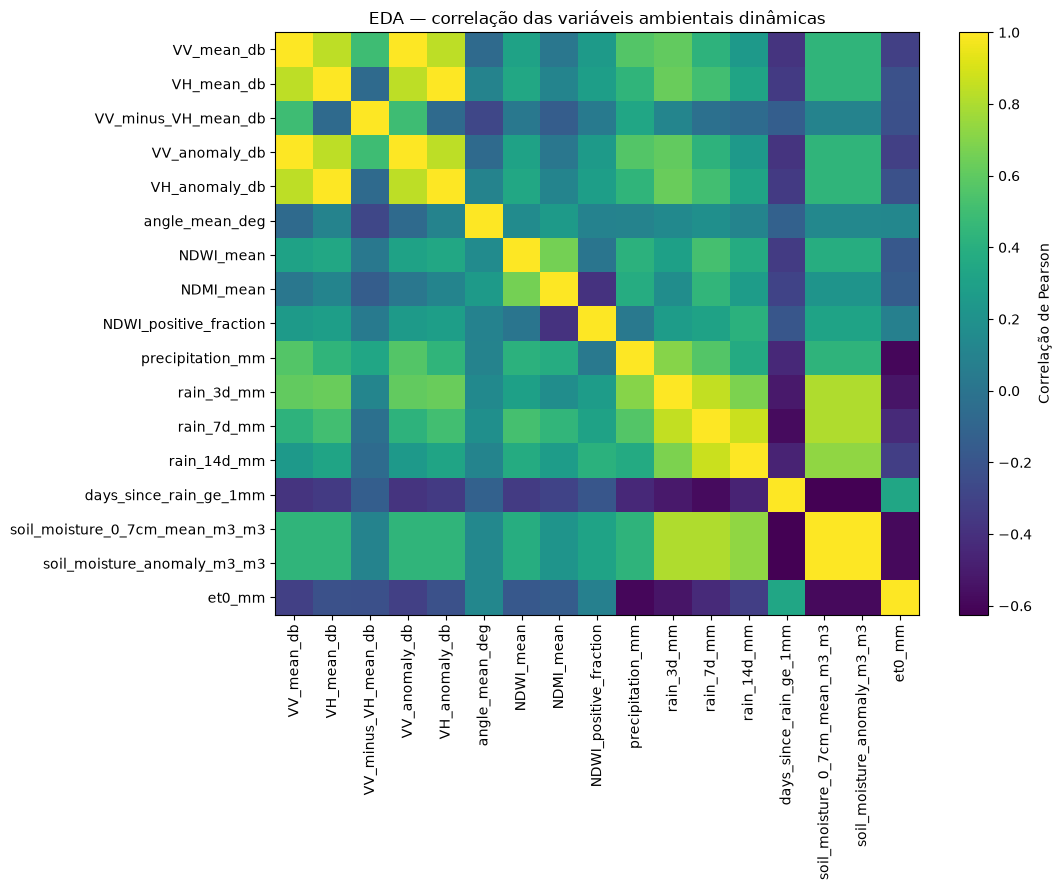

In [49]:
if (
    correlacao_dinamica.shape[0]
    >= 2
):

    plt.figure(
        figsize=(11, 9)
    )

    imagem = plt.imshow(
        correlacao_dinamica.values,
        aspect="auto"
    )

    plt.xticks(
        range(
            len(
                correlacao_dinamica.columns
            )
        ),
        correlacao_dinamica.columns,
        rotation=90
    )

    plt.yticks(
        range(
            len(
                correlacao_dinamica.index
            )
        ),
        correlacao_dinamica.index
    )

    plt.colorbar(
        imagem,
        label="Correlação de Pearson"
    )

    plt.title(
        "EDA — correlação das variáveis ambientais dinâmicas"
    )

    plt.tight_layout()
    plt.show()

## 10.6 — Catálogo de features para handoff

A EDA entrega as features, mas não decide o algoritmo de ML.

Prioridades sugeridas:

### Dinâmicas — alta prioridade

- anomalia relativa de VV;
- anomalia relativa de VH;
- VV − VH;
- ângulo de incidência;
- chuva 3/7/14 dias;
- dias desde chuva;
- umidade de reanálise;
- NDWI;
- NDMI;
- distância temporal até Sentinel-2.

### Estáticas — alta prioridade

- argila;
- areia;
- silte;
- declividade;
- elevação relativa;
- relevo local;
- distância até água histórica;
- ocorrência histórica de água.

### Interações a testar no ML

- radar × chuva;
- radar × NDWI;
- chuva × argila;
- chuva × declividade;
- chuva × elevação relativa;
- água histórica × elevação relativa.

Essas interações são hipóteses para teste, não regras fixas.

In [50]:
catalogo_features = pd.DataFrame(
    [
        {
            "feature": "VV_anomaly_db",
            "fonte": "Sentinel-1",
            "tipo": "dinamica",
            "prioridade": "alta",
            "observacao": "Desvio de VV em relação à mediana da mesma direção de órbita."
        },
        {
            "feature": "VH_anomaly_db",
            "fonte": "Sentinel-1",
            "tipo": "dinamica",
            "prioridade": "alta",
            "observacao": "Desvio de VH em relação à mediana da mesma direção de órbita."
        },
        {
            "feature": "VV_minus_VH_mean_db",
            "fonte": "Sentinel-1",
            "tipo": "dinamica",
            "prioridade": "alta",
            "observacao": "Diferença relativa entre polarizações."
        },
        {
            "feature": "NDWI_mean",
            "fonte": "Sentinel-2",
            "tipo": "dinamica",
            "prioridade": "alta",
            "observacao": "Contexto espectral de água superficial."
        },
        {
            "feature": "NDMI_mean",
            "fonte": "Sentinel-2",
            "tipo": "dinamica",
            "prioridade": "media",
            "observacao": "Conteúdo de água na cobertura/vegetação."
        },
        {
            "feature": "rain_3d_mm",
            "fonte": "Open-Meteo",
            "tipo": "dinamica",
            "prioridade": "alta",
            "observacao": "Precipitação antecedente."
        },
        {
            "feature": "rain_7d_mm",
            "fonte": "Open-Meteo",
            "tipo": "dinamica",
            "prioridade": "alta",
            "observacao": "Precipitação antecedente."
        },
        {
            "feature": "rain_14d_mm",
            "fonte": "Open-Meteo",
            "tipo": "dinamica",
            "prioridade": "alta",
            "observacao": "Memória hídrica mais longa."
        },
        {
            "feature": "soil_moisture_0_7cm_mean_m3_m3",
            "fonte": "Open-Meteo",
            "tipo": "dinamica",
            "prioridade": "media",
            "observacao": "Reanálise/modelagem; não é sensor local."
        },
        {
            "feature": "distance_any_water_min_m",
            "fonte": "JRC",
            "tipo": "estatica",
            "prioridade": "alta",
            "observacao": "Distância aproximada até água histórica."
        },
        {
            "feature": "relative_elevation_aoi_vs_1km_m",
            "fonte": "SRTM",
            "tipo": "estatica",
            "prioridade": "alta",
            "observacao": "Posição relativa do terreno na vizinhança."
        },
        {
            "feature": "slope_aoi_mean_deg",
            "fonte": "SRTM",
            "tipo": "estatica",
            "prioridade": "alta",
            "observacao": "Declividade média."
        },
        {
            "feature": "clay_pct",
            "fonte": "SoilGrids",
            "tipo": "estatica",
            "prioridade": "alta",
            "observacao": "Textura estimada nas camadas superficiais."
        },
        {
            "feature": "sand_pct",
            "fonte": "SoilGrids",
            "tipo": "estatica",
            "prioridade": "alta",
            "observacao": "Textura estimada nas camadas superficiais."
        },
    ]
)

catalogo_features

,feature,fonte,tipo,prioridade,observacao
0,VV_anomaly_db,Sentinel-1,dinamica,alta,Desvio de VV em relação à mediana da mesma dir...
1,VH_anomaly_db,Sentinel-1,dinamica,alta,Desvio de VH em relação à mediana da mesma dir...
2,VV_minus_VH_mean_db,Sentinel-1,dinamica,alta,Diferença relativa entre polarizações.
3,NDWI_mean,Sentinel-2,dinamica,alta,Contexto espectral de água superficial.
4,NDMI_mean,Sentinel-2,dinamica,media,Conteúdo de água na cobertura/vegetação.
5,rain_3d_mm,Open-Meteo,dinamica,alta,Precipitação antecedente.
6,rain_7d_mm,Open-Meteo,dinamica,alta,Precipitação antecedente.
7,rain_14d_mm,Open-Meteo,dinamica,alta,Memória hídrica mais longa.
8,soil_moisture_0_7cm_mean_m3_m3,Open-Meteo,dinamica,media,Reanálise/modelagem; não é sensor local.
9,distance_any_water_min_m,JRC,estatica,alta,Distância aproximada até água histórica.


## 10.7 — Limpeza final, persistência e validação no Oracle

A base ambiental é limpa, filtrada e editada **dentro desta EDA** antes de qualquer persistência.

Depois da limpeza, os registros são gravados diretamente na tabela Oracle:

```text
TB_ML_AMBIENTAL
```

Não será criado CSV, Excel, SQLite ou diretório intermediário.

### Tratamentos desta etapa

A limpeza final executa:

1. normalização dos nomes das colunas;
2. conversão segura de datas e valores numéricos;
3. remoção de duplicatas exatas;
4. conversão de `+inf/-inf` para ausente antes da imputação;
5. remoção de observações sem data;
6. controle mínimo de pixels válidos;
7. filtro de cenas ópticas com excesso de nuvens;
8. remoção de colunas com mais de 50% de ausência;
9. tratamento numérico por mediana;
10. clipping exploratório P1–P99 na matriz destinada ao ML;
11. remoção de features constantes;
12. redução de redundância quando `|correlação| > 0.95`.

A EDA original continua mostrando os dados antes desta preparação. Esta etapa produz a **matriz candidata para o próximo estágio de modelagem**.

> Ainda não existe um target operacional real de atolamento/segurança. Assim, podemos validar a matriz de features sem afirmar que o treino supervisionado já está liberado.

In [51]:
import hashlib
import json
import sys

import numpy as np
import pandas as pd

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from app.core.config_db import configurar_banco
from app.core.database import db


def normalizar_colunas(df):
    df = df.copy()
    df.columns = [
        str(col).strip().lower().replace(" ", "_")
        for col in df.columns
    ]
    return df


def converter_tipos(df):
    df = df.copy()

    for col in ["date", "s2_date"]:
        if col in df.columns:
            df[col] = pd.to_datetime(
                df[col],
                errors="coerce"
            )

    for col in df.columns:
        if col in {"date", "s2_date", "orbit_pass", "platform"}:
            continue

        if not pd.api.types.is_numeric_dtype(df[col]):
            numeric = pd.to_numeric(
                df[col],
                errors="coerce"
            )

            if numeric.notna().sum() >= max(
                5,
                int(len(df) * 0.8)
            ):
                df[col] = numeric

    return df


def limpar_filtrar_editar(df):
    df = df.copy()

    # Remove somente duplicatas exatamente iguais.
    df = df.drop_duplicates().reset_index(drop=True)

    # Data principal é obrigatória.
    if "date" in df.columns:
        df = (
            df
            .dropna(subset=["date"])
            .sort_values("date")
            .reset_index(drop=True)
        )

    # Infinitos não entram no pipeline numérico.
    numeric_cols = df.select_dtypes(include=["number"]).columns

    if len(numeric_cols):
        df[numeric_cols] = df[numeric_cols].replace(
            [np.inf, -np.inf],
            np.nan
        )

    # Qualidade mínima de cobertura espacial.
    for col, minimo in {
        "valid_pixels_s1": 500,
        "valid_pixels_s2": 100
    }.items():
        if col in df.columns:
            df = df[
                df[col].fillna(0) >= minimo
            ].copy()

    # Sentinel-2: cenas muito nubladas ficam fora da matriz.
    if "cloud_pct_scene" in df.columns:
        df = df[
            df["cloud_pct_scene"].fillna(100) <= 25
        ].copy()

    # Remove colunas praticamente indisponíveis.
    colunas_quase_vazias = [
        col
        for col in df.columns
        if df[col].isna().mean() > 0.5
    ]

    if colunas_quase_vazias:
        df = df.drop(columns=colunas_quase_vazias)

    # Tratamento numérico.
    for col in df.select_dtypes(include=["number"]).columns:
        if col in {
            "farm_latitude",
            "farm_longitude",
            "aoi_buffer_m"
        }:
            continue

        serie = df[col]

        if not serie.notna().any():
            continue

        q01 = serie.quantile(0.01)
        q99 = serie.quantile(0.99)
        mediana = serie.median()

        if pd.notna(q01) and pd.notna(q99):
            df[col] = (
                serie
                .clip(lower=q01, upper=q99)
                .fillna(mediana)
            )
        else:
            df[col] = serie.fillna(mediana)

    # Remove constantes.
    colunas_controle = {
        "farm_latitude",
        "farm_longitude",
        "aoi_buffer_m",
        "ml_training_ready"
    }

    candidatos = [
        col
        for col in df.select_dtypes(include=["number"]).columns
        if col not in colunas_controle
    ]

    constantes = [
        col
        for col in candidatos
        if df[col].var(ddof=0) <= 1e-8
    ]

    if constantes:
        df = df.drop(columns=constantes)
        candidatos = [
            col
            for col in candidatos
            if col not in constantes
        ]

    # Reduz redundância extrema.
    if len(candidatos) >= 2:
        correlacao = df[candidatos].corr().abs()
        redundantes = set()

        for indice, coluna in enumerate(correlacao.columns):
            for linha in correlacao.columns[indice + 1:]:
                valor = correlacao.loc[linha, coluna]

                if pd.notna(valor) and valor > 0.95:
                    redundantes.add(linha)

        if redundantes:
            df = df.drop(columns=sorted(redundantes))

    df["dataset_stage"] = "environmental_cleaned_stage"
    df["ml_training_ready"] = 0
    df["target_status"] = "missing_label"

    return df.reset_index(drop=True)


def valor_coluna(row, nomes):
    for nome in nomes:
        if nome in row.index and pd.notna(row[nome]):
            return row[nome]
    return None


df_pre_limpeza = converter_tipos(
    normalizar_colunas(df_ambiental)
)

clean_df = limpar_filtrar_editar(
    df_pre_limpeza
)

if clean_df.empty:
    raise ValueError(
        "A limpeza removeu todos os registros; "
        "a carga Oracle foi cancelada."
    )

print("Linhas antes da limpeza:", len(df_pre_limpeza))
print("Linhas após a limpeza:", len(clean_df))
print("Colunas antes da limpeza:", df_pre_limpeza.shape[1])
print("Colunas após a limpeza:", clean_df.shape[1])

Linhas antes da limpeza: 35
Linhas após a limpeza: 28
Colunas antes da limpeza: 70
Colunas após a limpeza: 35


### Persistência direta no Oracle

Nenhum arquivo intermediário será criado.

O `MERGE` permite atualizar registros já existentes e inserir somente os novos.

In [52]:
configurar_banco()

conn = db.get_connection()
cursor = conn.cursor()

merge_sql = """
    MERGE INTO TB_ML_AMBIENTAL destino
    USING (
        SELECT
            :fonte fonte,
            :data_observacao data_observacao,
            :latitude latitude,
            :longitude longitude,
            :features_json features_json,
            :hash_registro hash_registro
        FROM dual
    ) origem
    ON (
        destino.HASH_REGISTRO = origem.hash_registro
    )
    WHEN MATCHED THEN UPDATE SET
        destino.DATA_OBSERVACAO = origem.data_observacao,
        destino.LATITUDE = origem.latitude,
        destino.LONGITUDE = origem.longitude,
        destino.FEATURES_JSON = origem.features_json
    WHEN NOT MATCHED THEN INSERT (
        FONTE,
        DATA_OBSERVACAO,
        LATITUDE,
        LONGITUDE,
        FEATURES_JSON,
        HASH_REGISTRO
    ) VALUES (
        origem.fonte,
        origem.data_observacao,
        origem.latitude,
        origem.longitude,
        origem.features_json,
        origem.hash_registro
    )
"""

registros_oracle = []

for _, row in clean_df.iterrows():
    dados = {
        str(col): (
            None
            if pd.isna(valor)
            else valor
        )
        for col, valor in row.to_dict().items()
    }

    data_observacao = (
        dados.get("date")
        or dados.get("s2_date")
    )

    if data_observacao is None or pd.isna(data_observacao):
        raise ValueError(
            "Registro ambiental sem data após a limpeza."
        )

    data_observacao = pd.Timestamp(
        data_observacao
    ).to_pydatetime()

    features_json = json.dumps(
        dados,
        ensure_ascii=False,
        default=str
    )

    hash_registro = hashlib.sha256(
        (
            "EDA_AMBIENTAL|"
            + data_observacao.date().isoformat()
        ).encode("utf-8")
    ).hexdigest()

    registros_oracle.append(
        {
            "fonte": "EDA_AMBIENTAL",
            "data_observacao": data_observacao,
            "latitude": valor_coluna(
                row,
                ["farm_latitude", "latitude"]
            ),
            "longitude": valor_coluna(
                row,
                ["farm_longitude", "longitude"]
            ),
            "features_json": features_json,
            "hash_registro": hash_registro
        }
    )

try:
    cursor.executemany(
        merge_sql,
        registros_oracle
    )
    conn.commit()

finally:
    cursor.close()
    db.release_connection(conn)

print(
    "Registros limpos gravados no Oracle:",
    len(registros_oracle)
)

Infraestrutura de dados: Sincronizada.
Registros limpos gravados no Oracle: 28


# FASE 11 — Validação visual da limpeza e prontidão para Machine Learning

Esta fase fecha o EDA com evidências objetivas de que:

1. as fontes ambientais foram integradas;
2. a limpeza não eliminou a base;
3. a matriz numérica não contém `NaN` ou infinito;
4. as features restantes apresentam variância;
5. a redundância extrema foi reduzida;
6. existe cobertura temporal;
7. a matriz de features pode ser entregue para a etapa de Machine Learning.

## Importante

**Pronta para montar o ML** e **pronta para treino supervisionado** são coisas diferentes.

A primeira depende da qualidade das features.

A segunda também exige um target real.

Por isso o checklist final mostra essas duas condições separadamente.

## 11.1 — Matriz candidata de features

Campos administrativos e de controle são excluídos desta auditoria.

In [53]:
COLUNAS_CONTROLE_ML = {
    "farm_latitude",
    "farm_longitude",
    "aoi_buffer_m",
    "ml_training_ready"
}


def matriz_numerica_ml(df):
    numeric = df.select_dtypes(
        include=[np.number]
    ).copy()

    return numeric.drop(
        columns=[
            col
            for col in COLUNAS_CONTROLE_ML
            if col in numeric.columns
        ],
        errors="ignore"
    )


X_antes = matriz_numerica_ml(
    df_pre_limpeza
)

X_ml = matriz_numerica_ml(
    clean_df
)

print("Shape numérico antes:", X_antes.shape)
print("Shape candidato para ML:", X_ml.shape)

Shape numérico antes: (35, 58)
Shape candidato para ML: (28, 24)


## 11.2 — Qualidade antes × depois da limpeza

O gráfico compara:

- percentual de células ausentes;
- percentual de valores infinitos;
- percentual de linhas numéricas exatamente duplicadas.

Uma queda após o tratamento reforça que a limpeza cumpriu sua função.

In [54]:
def metricas_qualidade(X):
    if X.empty:
        return {
            "missing_pct": 100.0,
            "infinite_pct": 0.0,
            "duplicate_rows_pct": 0.0
        }

    total_celulas = X.shape[0] * X.shape[1]

    missing_pct = (
        X.isna().sum().sum()
        / total_celulas
        * 100
        if total_celulas
        else 0.0
    )

    valores = X.to_numpy(
        dtype=float,
        copy=True
    )

    infinite_pct = (
        np.isinf(valores).sum()
        / total_celulas
        * 100
        if total_celulas
        else 0.0
    )

    duplicate_rows_pct = (
        X.duplicated().mean()
        * 100
        if len(X)
        else 0.0
    )

    return {
        "missing_pct": float(missing_pct),
        "infinite_pct": float(infinite_pct),
        "duplicate_rows_pct": float(duplicate_rows_pct)
    }


qualidade_antes = metricas_qualidade(
    X_antes
)

qualidade_depois = metricas_qualidade(
    X_ml
)

comparacao_qualidade = pd.DataFrame(
    {
        "Métrica": [
            "Ausentes",
            "Infinitos",
            "Linhas duplicadas"
        ],
        "Antes (%)": [
            qualidade_antes["missing_pct"],
            qualidade_antes["infinite_pct"],
            qualidade_antes["duplicate_rows_pct"]
        ],
        "Depois (%)": [
            qualidade_depois["missing_pct"],
            qualidade_depois["infinite_pct"],
            qualidade_depois["duplicate_rows_pct"]
        ]
    }
)

display(comparacao_qualidade)

,Métrica,Antes (%),Depois (%)
0,Ausentes,17.7340,0.0000
1,Infinitos,0.0000,0.0000
2,Linhas duplicadas,0.0000,0.0000


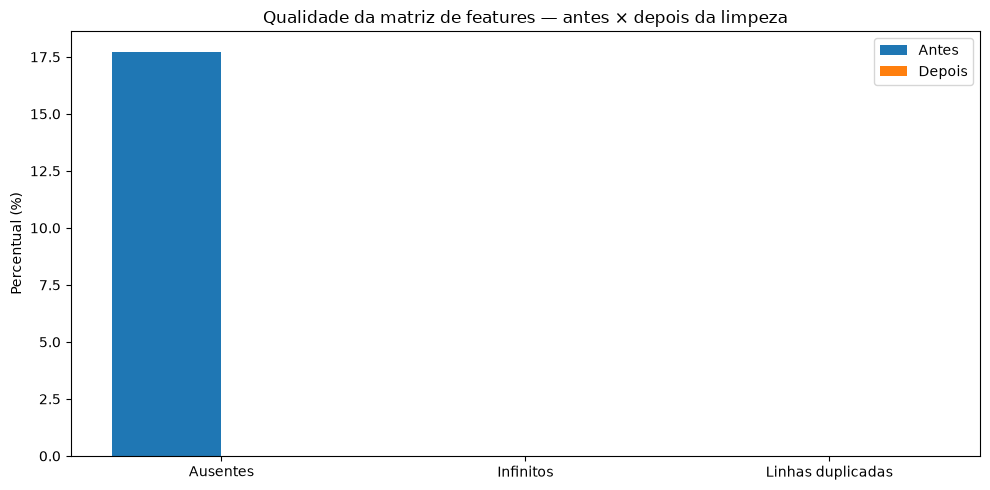

In [55]:
x = np.arange(
    len(comparacao_qualidade)
)

largura = 0.36

plt.figure(figsize=(10, 5))

plt.bar(
    x - largura / 2,
    comparacao_qualidade["Antes (%)"],
    width=largura,
    label="Antes"
)

plt.bar(
    x + largura / 2,
    comparacao_qualidade["Depois (%)"],
    width=largura,
    label="Depois"
)

plt.xticks(
    x,
    comparacao_qualidade["Métrica"]
)

plt.ylabel("Percentual (%)")

plt.title(
    "Qualidade da matriz de features — antes × depois da limpeza"
)

plt.legend()
plt.tight_layout()
plt.show()

## 11.3 — Retenção de registros

Uma limpeza adequada não deve melhorar as métricas apenas porque apagou quase toda a base.

Por isso também medimos a retenção de observações.

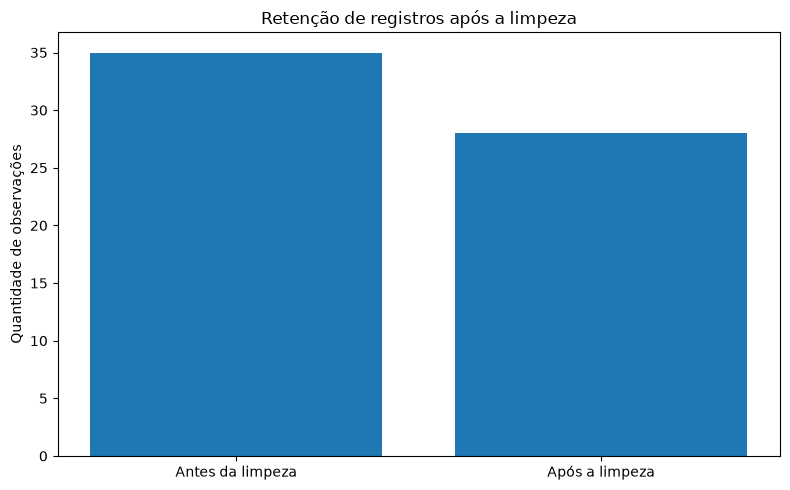

Retenção de observações: 80.00%


In [56]:
retencao_registros_pct = (
    len(clean_df)
    / len(df_pre_limpeza)
    * 100
    if len(df_pre_limpeza)
    else 0.0
)

comparacao_linhas = pd.DataFrame(
    {
        "Etapa": [
            "Antes da limpeza",
            "Após a limpeza"
        ],
        "Registros": [
            len(df_pre_limpeza),
            len(clean_df)
        ]
    }
)

plt.figure(figsize=(8, 5))

plt.bar(
    comparacao_linhas["Etapa"],
    comparacao_linhas["Registros"]
)

plt.ylabel("Quantidade de observações")

plt.title(
    "Retenção de registros após a limpeza"
)

plt.tight_layout()
plt.show()

print(
    f"Retenção de observações: "
    f"{retencao_registros_pct:.2f}%"
)

## 11.4 — Variância e redundância

A matriz final é verificada para confirmar que:

- não restaram features constantes;
- não restaram pares com correlação absoluta acima de `0.95`.

In [57]:
variancias_ml = X_ml.var(
    ddof=0
)

features_constantes_ml = (
    variancias_ml[
        variancias_ml <= 1e-8
    ]
    .index
    .tolist()
)

pares_redundantes_ml = []

if X_ml.shape[1] >= 2:
    corr_ml = X_ml.corr().abs()

    for indice, coluna in enumerate(
        corr_ml.columns
    ):
        for linha in corr_ml.columns[
            indice + 1:
        ]:
            valor = corr_ml.loc[
                linha,
                coluna
            ]

            if (
                pd.notna(valor)
                and valor > 0.95
            ):
                pares_redundantes_ml.append(
                    (
                        coluna,
                        linha,
                        float(valor)
                    )
                )

print(
    "Features numéricas candidatas:",
    X_ml.shape[1]
)

print(
    "Features constantes:",
    len(features_constantes_ml)
)

print(
    "Pares com |correlação| > 0.95:",
    len(pares_redundantes_ml)
)

Features numéricas candidatas: 24
Features constantes: 0
Pares com |correlação| > 0.95: 0


## 11.5 — Cobertura temporal

Sem variação temporal, parte importante do propósito do EDA ambiental seria perdida.

In [58]:
if "date" in clean_df.columns:
    datas_clean = (
        pd.to_datetime(
            clean_df["date"],
            errors="coerce"
        )
        .dropna()
        .sort_values()
    )
else:
    datas_clean = pd.Series(
        dtype="datetime64[ns]"
    )

cobertura_temporal = {
    "observacoes": int(len(datas_clean)),
    "datas_distintas": int(
        datas_clean.nunique()
    ),
    "intervalo_dias": int(
        (
            datas_clean.max()
            - datas_clean.min()
        ).days
    )
    if len(datas_clean)
    else 0
}

display(
    pd.DataFrame(
        [cobertura_temporal]
    )
)

,observacoes,datas_distintas,intervalo_dias
0,28,28,175


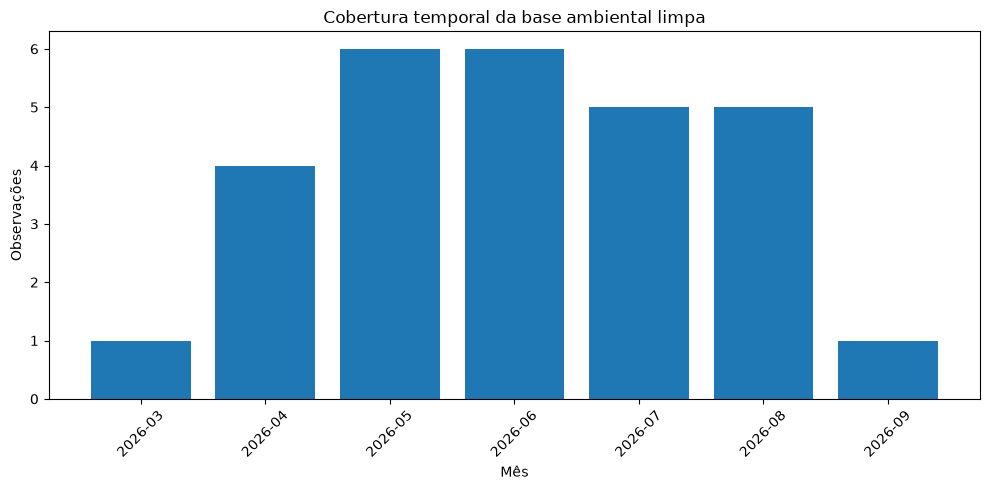

In [59]:
if len(datas_clean):
    contagem_mensal = (
        pd.DataFrame(
            {"date": datas_clean}
        )
        .assign(
            mes=lambda df: (
                df["date"]
                .dt
                .to_period("M")
                .astype(str)
            )
        )
        .groupby("mes")
        .size()
        .rename("observacoes")
        .reset_index()
    )

    plt.figure(figsize=(10, 5))

    plt.bar(
        contagem_mensal["mes"],
        contagem_mensal["observacoes"]
    )

    plt.xlabel("Mês")
    plt.ylabel("Observações")

    plt.title(
        "Cobertura temporal da base ambiental limpa"
    )

    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

## 11.6 — Evidência de integração do EDA

Este gráfico coloca sinais de fontes diferentes na mesma escala **somente para visualização**:

- anomalia relativa de `VV`;
- chuva acumulada de 7 dias;
- umidade do solo de reanálise.

A padronização não altera `clean_df`.

O objetivo é mostrar que o pipeline realmente integrou radar e clima em um mesmo eixo temporal.

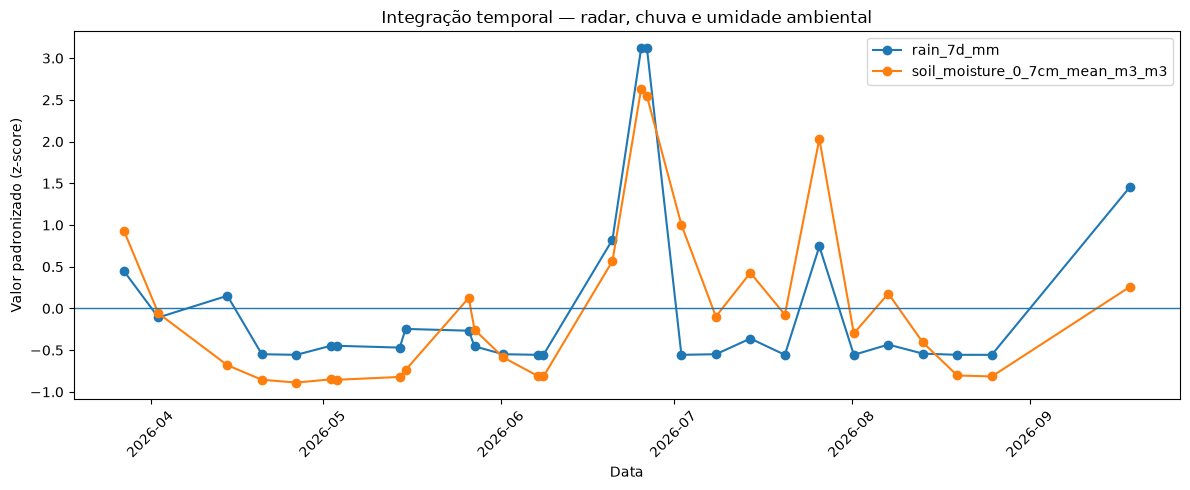

In [60]:
sinais_integrados = [
    coluna
    for coluna in [
        "vv_anomaly_db",
        "rain_7d_mm",
        "soil_moisture_0_7cm_mean_m3_m3"
    ]
    if coluna in clean_df.columns
]

if (
    "date" in clean_df.columns
    and len(sinais_integrados) >= 2
):
    dados_grafico = clean_df[
        ["date", *sinais_integrados]
    ].copy()

    dados_grafico["date"] = pd.to_datetime(
        dados_grafico["date"],
        errors="coerce"
    )

    dados_grafico = (
        dados_grafico
        .dropna(subset=["date"])
        .sort_values("date")
    )

    colunas_z = []

    for coluna in sinais_integrados:
        desvio = dados_grafico[
            coluna
        ].std(ddof=0)

        if (
            pd.notna(desvio)
            and desvio > 0
        ):
            nome_z = f"{coluna}__z"

            dados_grafico[nome_z] = (
                (
                    dados_grafico[coluna]
                    - dados_grafico[coluna].mean()
                )
                / desvio
            )

            colunas_z.append(nome_z)

    if colunas_z:
        plt.figure(figsize=(12, 5))

        for coluna in colunas_z:
            plt.plot(
                dados_grafico["date"],
                dados_grafico[coluna],
                marker="o",
                label=coluna.replace(
                    "__z",
                    ""
                )
            )

        plt.axhline(
            0,
            linewidth=1
        )

        plt.xlabel("Data")
        plt.ylabel(
            "Valor padronizado (z-score)"
        )

        plt.title(
            "Integração temporal — radar, chuva e umidade ambiental"
        )

        plt.legend()
        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.show()

else:
    print(
        "Não há pelo menos dois sinais dinâmicos "
        "disponíveis para o gráfico integrado."
    )

## 11.7 — Checklist final de prontidão

Critérios avaliados:

- sem ausentes na matriz numérica;
- sem infinitos;
- features com variância;
- sem redundância extrema acima de 0.95;
- cobertura temporal válida;
- target operacional real disponível.

O target aparece separado dos demais justamente para não confundir **features prontas** com **treino supervisionado pronto**.

In [61]:
sem_nulos_ml = (
    X_ml.isna()
    .sum()
    .sum()
    == 0
)

sem_infinitos_ml = (
    False
    if X_ml.empty
    else bool(
        np.isfinite(
            X_ml.to_numpy(
                dtype=float
            )
        ).all()
    )
)

sem_constantes_ml = (
    len(features_constantes_ml) == 0
    and X_ml.shape[1] > 0
)

sem_redundancia_ml = (
    len(pares_redundantes_ml) == 0
)

cobertura_temporal_ok = (
    cobertura_temporal[
        "datas_distintas"
    ] >= 3
    and cobertura_temporal[
        "intervalo_dias"
    ] > 0
)

target_disponivel = False

if "target_status" in clean_df.columns:
    status_target = (
        clean_df[
            "target_status"
        ]
        .dropna()
        .astype(str)
        .str.lower()
    )

    target_disponivel = bool(
        len(status_target)
        and not status_target.isin(
            [
                "missing_label",
                "missing",
                "sem_target"
            ]
        ).all()
    )

pronta_features_ml = all(
    [
        sem_nulos_ml,
        sem_infinitos_ml,
        sem_constantes_ml,
        sem_redundancia_ml,
        cobertura_temporal_ok
    ]
)

pronta_treino_supervisionado = (
    pronta_features_ml
    and target_disponivel
)

checklist_ml = pd.DataFrame(
    {
        "Critério": [
            "Sem ausentes",
            "Sem infinitos",
            "Features com variância",
            "Sem redundância > 0.95",
            "Cobertura temporal",
            "Target real disponível"
        ],
        "OK": [
            sem_nulos_ml,
            sem_infinitos_ml,
            sem_constantes_ml,
            sem_redundancia_ml,
            cobertura_temporal_ok,
            target_disponivel
        ]
    }
)

checklist_ml["Valor"] = (
    checklist_ml["OK"]
    .astype(int)
)

display(checklist_ml)

,Critério,OK,Valor
0,Sem ausentes,True,1
1,Sem infinitos,True,1
2,Features com variância,True,1
3,Sem redundância > 0.95,True,1
4,Cobertura temporal,True,1
5,Target real disponível,False,0


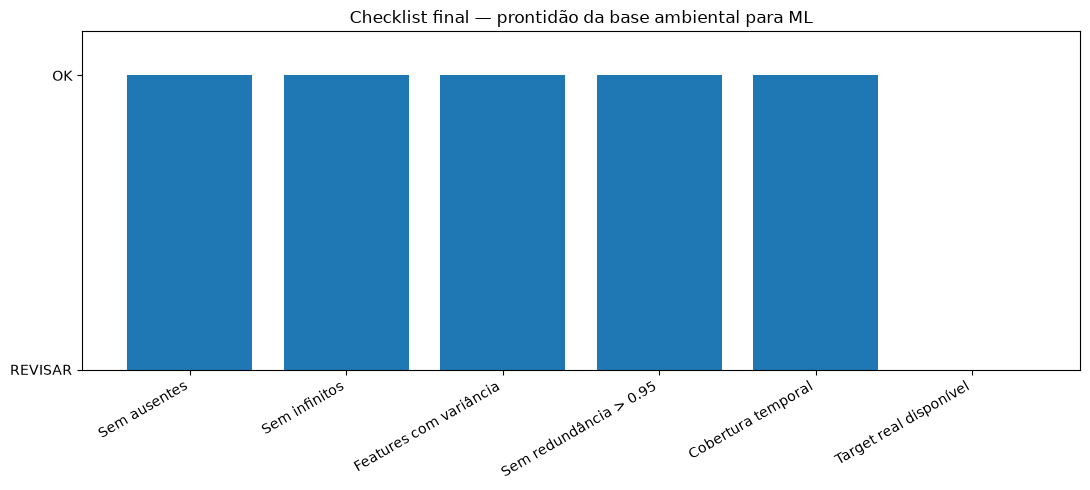

In [62]:
plt.figure(figsize=(11, 5))

plt.bar(
    checklist_ml["Critério"],
    checklist_ml["Valor"]
)

plt.ylim(0, 1.15)

plt.yticks(
    [0, 1],
    ["REVISAR", "OK"]
)

plt.title(
    "Checklist final — prontidão da base ambiental para ML"
)

plt.xticks(
    rotation=30,
    ha="right"
)

plt.tight_layout()
plt.show()

## 11.8 — Resultado final automático

A mensagem abaixo não escolhe algoritmo e não cria target.

Ela apenas resume a prontidão técnica da matriz de features.

In [63]:
print("=" * 72)
print("RESULTADO FINAL DA EDA AMBIENTAL")
print("=" * 72)

print(
    f"Registros após limpeza: "
    f"{len(clean_df)}"
)

print(
    f"Features numéricas candidatas: "
    f"{X_ml.shape[1]}"
)

print(
    f"Retenção de registros: "
    f"{retencao_registros_pct:.2f}%"
)

print()

if pronta_features_ml:
    print(
        "✅ MATRIZ DE FEATURES PRONTA "
        "PARA O PRÓXIMO ESTÁGIO DE ML."
    )
else:
    print(
        "⚠️ A MATRIZ DE FEATURES AINDA "
        "POSSUI PONTOS A REVISAR."
    )

print()

if pronta_treino_supervisionado:
    print(
        "✅ TARGET DISPONÍVEL: base tecnicamente "
        "apta para preparação do treino supervisionado."
    )
else:
    print(
        "ℹ️ O TARGET OPERACIONAL REAL AINDA NÃO ESTÁ DISPONÍVEL."
    )

    print(
        "A EDA e a preparação das FEATURES podem ser "
        "consideradas concluídas, mas o treino supervisionado "
        "deve aguardar o target real ou usar uma estratégia "
        "não supervisionada validada."
    )

RESULTADO FINAL DA EDA AMBIENTAL
Registros após limpeza: 28
Features numéricas candidatas: 24
Retenção de registros: 80.00%

✅ MATRIZ DE FEATURES PRONTA PARA O PRÓXIMO ESTÁGIO DE ML.

ℹ️ O TARGET OPERACIONAL REAL AINDA NÃO ESTÁ DISPONÍVEL.
A EDA e a preparação das FEATURES podem ser consideradas concluídas, mas o treino supervisionado deve aguardar o target real ou usar uma estratégia não supervisionada validada.


# Conclusão — EDA Ambiental

Ao finalizar as Fases 0 a 11, o MAIA passa a ter uma segunda linha de dados complementar à telemetria do trator:

```text
TELEMETRIA DO TRATOR
        +
SENTINEL-1
        +
SENTINEL-2
        +
ÁGUA HISTÓRICA
        +
TOPOGRAFIA
        +
SOILGRIDS
        +
CHUVA ANTECEDENTE
```

## O que esta EDA entrega

- pipeline reproduzível;
- autenticação GEE documentada;
- AOI rastreável;
- série real de radar;
- índices ópticos;
- contexto de água;
- relevo;
- textura do solo;
- precipitação antecedente;
- integração multivariada;
- limpeza final;
- redução de features constantes e extremamente redundantes;
- validação visual da qualidade;
- checklist de prontidão da matriz de features;
- persistência direta no Oracle.

## Interpretação correta da prontidão

Se a Fase 11 retornar:

```text
MATRIZ DE FEATURES PRONTA PARA O PRÓXIMO ESTÁGIO DE ML
```

isso significa que a engenharia e a qualidade básica das entradas passaram pelos testes definidos.

Isso **não cria automaticamente um problema supervisionado**.

Para treinar um classificador do tipo:

```text
atolou / não atolou
```

ainda será necessário obter um target operacional real.

Caso esse target não exista, o grupo deverá estudar uma estratégia não supervisionada, semi-supervisionada ou outra formulação coerente com os dados disponíveis.